# 01b · Exploratory Data Analysis (MMM deep-dive) — Tchibo Marketing Sales Prediction

**Business question:** can total daily demand (sales) be forecast from the marketing budget for short-term steering?
**Acceptance KPI:** `MAE / mean(sales) ≤ 15 %` · **Lens:** Marketing-Mix Modelling (MMM) · **Scope:** Phase 1 of [PLAN.md](../PLAN.md)

This notebook is a complete exploratory analysis of `data/DataScienceMarketingUseCase.xlsx`. It audits data quality, profiles the
target and every channel, studies spend, media efficiency and correlations, isolates the catalog's delayed effect, and closes with
an MMM-readiness assessment and the answers to the case-study questions. It is self-contained (no project imports), so it runs
independently of `src/`.

Every chart title states its takeaway. Charts are exported to `reports/figures/eda/` for the presentation.

## Executive summary

**Data.** 8,740 rows in long, *shuffled* format: 12 channels × 732 days (1 Jan 2023 – 1 Jan 2025, the last day alone in 2025).
Only **7 channels carry costs** (SEA, Catalog, Display, Affiliate, Social Media, Display Network, PSM); 5 are sales-only. 44 channel-days
are missing (TV 38, Catalog 4, Owned 2) — negligible for the target (< 0.1 % of sales). Catalog cost exists only on its **28 send-out days**.

**Target.** Total daily sales average **€787 K** (CV 0.36), right-skewed (skew 1.95; ≈ symmetric on log scale), non-stationary, and
**+20.7 % in 2024** with only **+12.4 % more spend**. Strong Q4, Tuesday & Sunday highs, and Christmas troughs (−65 % to −79 %).

**Five findings that shape the model**

1. **The catalog is the dominant demand driver — with a 3-day delay.** Same-day correlation with sales is −0.01, at lag 3 it is **0.40**.
   Sales peak on the Sunday after a Thursday send-out (**+99 %** weekday-adjusted), fade over ~2 weeks, and all five biggest days
   in the data are such Sundays. A 42-day catalog pause in autumn 2023 produced the weakest month (Sep 2023, €473 K/day).
2. **Halo: the catalog lifts other channels.** In the week after a send-out total demand is **+46 %**, and sales credited to SEO
   (+25 %), Direct Type-in (+20 %), Social (+36 %), Affiliate, PSM and SEA (+15–16 %) all rise → the catalog's attributed ROAS (2.1)
   understates it; model **total** sales.
3. **Some costs follow demand.** Affiliate cost is a commission on its own sales (r = 0.80; rate doubled from ~7 % to ~15 % in Feb 2024);
   SEA is click-billed (cost↔clicks r = 0.96). These two have the highest correlation with sales (0.76 / 0.72) and keep it after
   removing trend & calendar — a sign of **reverse causality**, not just effectiveness.
4. **Budgets follow the season.** Trend + calendar explain **33–52 %** of every digital channel's spend variance, digital spends correlate
   with each other (0.22–0.58), and all are always on → individual digital effects are **weakly identified**; most of their raw correlation
   with sales disappears once seasonality is removed (Display 0.56 → 0.39, Social 0.33 → 0.15).
5. **Two structural breaks.** Social Media changed regime on **1 Aug 2024** (spend ×3, clicks ×8 overnight, attributed sales ×10 within
   weeks); Affiliate's commission rate doubled in **Feb 2024**. The Q4-2024 hold-out lies entirely in the new regimes.

**Implications.** Model log/total sales with a trend, weekday & yearly seasonality, holiday/Black-Friday flags, a **delayed-peak catalog
adstock** (peak ≈ day 3, 90 % of response within ~12 days, max lag ~21), short adstock + saturation for digital spend, regime flags,
and regularisation / Bayesian priors (Meridian) for the weakly identified digital channels. Section 12 answers the brief's questions.

## Contents

1. [Setup](#1.-Setup)
2. [Load data & data dictionary](#2.-Load-data-&-data-dictionary)
3. [Data-quality audit](#3.-Data-quality-audit)
4. [Analytical daily tables](#4.-Analytical-daily-tables)
5. [Target: total daily sales](#5.-Target:-total-daily-sales)
6. [Channel landscape — attributed sales](#6.-Channel-landscape-—-attributed-sales)
7. [Marketing investment — costs](#7.-Marketing-investment-—-costs)
8. [Media funnel & efficiency](#8.-Media-funnel-&-efficiency)
9. [Correlation analysis](#9.-Correlation-analysis)
10. [Catalog deep-dive: delayed effect & halo](#10.-Catalog-deep-dive:-delayed-effect-&-halo)
11. [MMM readiness](#11.-MMM-readiness)
12. [Answers to the case-study questions](#12.-Answers-to-the-case-study-questions)
13. [Implications for data preparation & modelling](#13.-Implications-for-data-preparation-&-modelling)

## 1. Setup

In [1]:
from pathlib import Path
import warnings

import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from cycler import cycler
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy.cluster.hierarchy import leaves_list, linkage
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.simplefilter("ignore", InterpolationWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 220)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "DataScienceMarketingUseCase.xlsx"
FIG_DIR = ROOT / "reports" / "figures" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

**Chart system.** One validated categorical palette (colour-blind safe on adjacent pairs) is assigned to the seven *paid* channels in a fixed
order, so a channel keeps its colour in every chart. Channels without cost data share a neutral grey. Magnitude uses a single-hue blue
ramp; signed values (correlations, lifts) use a red ↔ grey ↔ blue diverging scale. No chart uses two y-axes.

In [2]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#b4b2a9"
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
ACCENT, NEGATIVE = CATEGORICAL[0], CATEGORICAL[7]
LIGHT_ACCENT, DARK_ACCENT = "#86b6ef", "#1c5cab"

SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f3f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
DIV = LinearSegmentedColormap.from_list(
    "div_red_blue", ["#9e2b2b", "#e34948", "#f1aaa8", "#f0efec", "#9ec5f4", "#3987e5", "#184f95"]
)
for cmap in (SEQ, DIV):
    cmap.set_bad(SURFACE)

# Channel taxonomy: paid channels carry costs, the rest are organic / untracked-spend channels.
PAID = ["SEA", "Catalog", "Display", "Affiliate", "Social Media", "Display Network", "PSM"]
PAID_DIGITAL = [c for c in PAID if c != "Catalog"]
UNPAID = ["Direct Type-in", "SEO", "TV", "Direct Referred", "Owned"]
CHANNELS = PAID + UNPAID
ORGANIC = "Organic & unpaid"
COLOR = {**dict(zip(PAID, CATEGORICAL)), **{c: NEUTRAL for c in UNPAID}, ORGANIC: NEUTRAL}
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (12, 4.5),
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2, "axes.labelsize": 9.5,
    "axes.titlesize": 10.5, "axes.titleweight": "semibold", "axes.titlecolor": INK,
    "axes.titlelocation": "left", "axes.titlepad": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "grid.linestyle": "-",
    "axes.prop_cycle": cycler(color=CATEGORICAL),
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "ytick.major.size": 0,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 8.5, "legend.labelcolor": INK_2,
    "legend.handlelength": 1.4,
})


def compact(x, _=None, prefix="€"):
    a = abs(x)
    if a >= 1e6:
        return f"{prefix}{x / 1e6:.1f}M"
    if a >= 1e3:
        return f"{prefix}{x / 1e3:.0f}K"
    return f"{prefix}{x:,.0f}"


EUR = mticker.FuncFormatter(compact)
NUM = mticker.FuncFormatter(lambda x, _: compact(x, prefix=""))
PCT = mticker.PercentFormatter(1.0, decimals=0)


def headline(fig, title):
    fig.suptitle(title, x=0.01, ha="left", fontsize=13, fontweight="semibold", color=INK)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")


def date_axis(ax, months=(1, 4, 7, 10), fmt="%b %y"):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=months))
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


def catalog_rug(ax, dates, label="Catalog send-out"):
    ax.vlines(dates, 0, 0.045, transform=ax.get_xaxis_transform(), color=COLOR["Catalog"],
              lw=1.6, label=label)


def heatmap(ax, data, cmap=SEQ, norm=None, fmt="{:.2f}", annot=True, cbar_label=None,
            fontsize=8, xrot=0, cbar=True, cbar_fmt=None):
    values = data.to_numpy(dtype=float)
    im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(data.shape[1]), data.columns, rotation=xrot,
                  ha="right" if xrot else "center")
    ax.set_yticks(range(data.shape[0]), data.index)
    ax.grid(False)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    if annot:
        for (i, j), v in np.ndenumerate(values):
            if np.isnan(v):
                continue
            r, g, b, _ = im.cmap(im.norm(v))
            ink = "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fontsize, color=ink)
    if cbar:
        cb = ax.figure.colorbar(im, ax=ax, shrink=0.85, pad=0.015, aspect=30)
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=0, labelsize=8)
        if cbar_fmt is not None:
            cb.ax.yaxis.set_major_formatter(cbar_fmt)
        if cbar_label:
            cb.set_label(cbar_label, color=INK_2, fontsize=9)
    return im


def ranked_bars(ax, s, color=ACCENT, fmt="{:.0%}", height=0.62, labels=None):
    # Horizontal bars, largest on top, value printed at the bar tip (labels overrides the text).
    s = s.sort_values()
    colors = [color.get(k, ACCENT) for k in s.index] if isinstance(color, dict) else color
    ax.barh(s.index, s.values, color=colors, height=height)
    for i, (k, v) in enumerate(s.items()):
        text = labels[k] if labels is not None else fmt.format(v)
        ax.text(v, i, f" {text} ", va="center", ha="left" if v >= 0 else "right",
                fontsize=8.5, color=INK_2)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.axvline(0, color=AXIS, lw=0.8)
    ax.margins(x=0.14)
    ax.tick_params(axis="y", length=0)

## 2. Load data & data dictionary

The brief mentions a `.csv`; we received an `.xlsx` with two sheets: `data` (long format, one row per `date × channel`) and `info`
(the column dictionary).

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="data")
info = pd.read_excel(DATA_PATH, sheet_name="info")

with pd.option_context("display.max_colwidth", None):
    display(info.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Column,Explanations
date,"Date of measurement for impressions, clicks, and sales"
channel,Marketing channel name
sales_by_channel,Demand value of the marketing channel
impressions,"Number of impressions of the marketing channel, for catalog it is the circulation"
clicks,Number of Marketing Channel Clicks
costs,"Sum of the marketing channel costs for the day of causation, e.g. display spend of the day or cost of the catalog for the day of the broadcast"


Two notes in the dictionary shape the whole analysis:

- **Catalog `impressions` = circulation** (printed copies), not ad views.
- **`costs` are booked on the *day of causation*** — e.g. the full printing & postage cost of a catalog lands on its send-out day,
  while its sales arrive over the following weeks. Spend and response are therefore *not* aligned in time.

In [4]:
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.dtypes.rename("dtype").to_frame().T)
display(raw.head(8))

Shape: 8,740 rows × 6 columns


,date,channel,sales_by_channel,impressions,clicks,costs
dtype,datetime64[ns],object,float64,float64,float64,float64


,date,channel,sales_by_channel,impressions,clicks,costs
0,2023-01-01,Direct Type-in,108813.944355,NaN,NaN,NaN
1,2023-01-08,Display,83345.701688,51629694.0,136982.0,2.363995e+04
2,2023-01-15,Display,93476.542650,59454941.0,185965.0,3.371848e+04
3,2023-01-28,SEA,185021.905417,6982917.0,142195.0,4.646078e+04
4,2023-01-23,SEO,109095.480860,NaN,NaN,NaN
5,2023-01-12,Catalog,74081.836626,2225161.0,0.0,1.622518e+06
6,2023-01-25,Affiliate,47198.453782,6395.0,13768.0,3.670125e+03
7,2023-02-27,Direct Type-in,124067.559995,NaN,NaN,NaN


## 3. Data-quality audit

### 3.1 Structural checks

In [5]:
num_cols = ["sales_by_channel", "impressions", "clicks", "costs"]
all_days = pd.date_range(raw["date"].min(), raw["date"].max(), freq="D")

structural = pd.Series({
    "Rows": f"{len(raw):,}",
    "Channels": raw["channel"].nunique(),
    "First date": raw["date"].min().date(),
    "Last date": raw["date"].max().date(),
    "Calendar days in range": len(all_days),
    "Distinct dates present": raw["date"].nunique(),
    "Rows sorted by date?": raw["date"].is_monotonic_increasing,
    "Duplicate (date, channel) pairs": raw.duplicated(["date", "channel"]).sum(),
    "Expected rows (days × channels)": f"{len(all_days) * raw['channel'].nunique():,}",
    "Missing (date, channel) rows": len(all_days) * raw["channel"].nunique() - len(raw),
    "Negative values (any metric)": int((raw[num_cols] < 0).sum().sum()),
    "Days in 2025": raw.loc[raw["date"].dt.year == 2025, "date"].nunique(),
}, name="value").to_frame()
display(structural)

raw = raw.sort_values(["date", "channel"]).reset_index(drop=True)

,value
Rows,"8,740"
Channels,12
First date,2023-01-01
Last date,2025-01-01
Calendar days in range,732
Distinct dates present,732
Rows sorted by date?,False
"Duplicate (date, channel) pairs",0
Expected rows (days × channels),"8,784"
"Missing (date, channel) rows",44


- The rows arrive **shuffled** — the file must be sorted before any time-series work.
- No duplicates and no negative values; every calendar day between 2023-01-01 and 2025-01-01 is present for *at least* one channel.
- **44 `(date, channel)` rows are missing** (detailed below), and **2025 is represented by a single day** — it must be excluded from
  yearly / monthly aggregations or flagged.

### 3.2 Which metric exists for which channel?

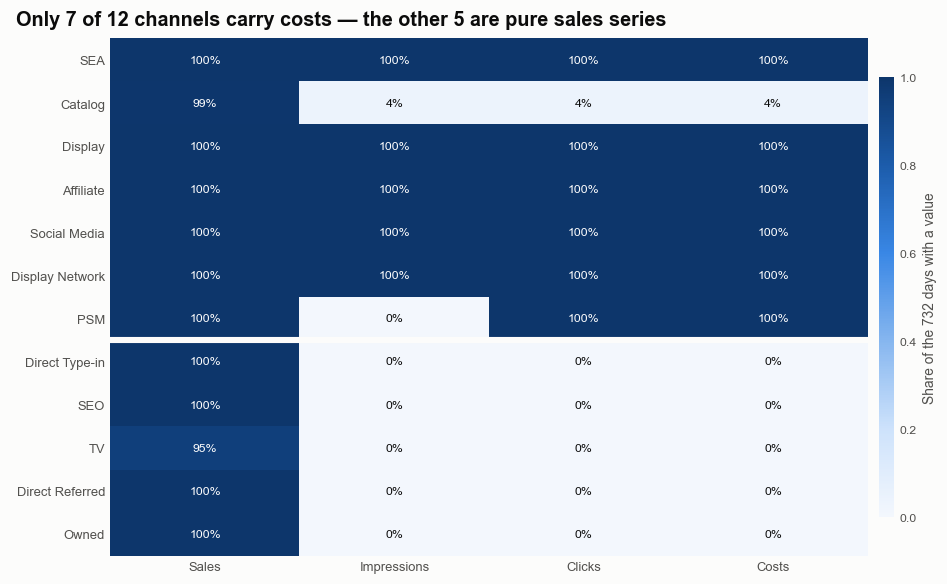

In [6]:
grid = (
    raw.set_index(["date", "channel"])
    .reindex(pd.MultiIndex.from_product([all_days, CHANNELS], names=["date", "channel"]))
)
availability = grid.notna().groupby(level="channel").mean().loc[CHANNELS]
availability.columns = ["Sales", "Impressions", "Clicks", "Costs"]

fig, ax = plt.subplots(figsize=(8.5, 5.2), layout="constrained")
heatmap(ax, availability, cmap=SEQ, fmt="{:.0%}", cbar_label="Share of the 732 days with a value")
ax.axhline(len(PAID) - 0.5, color=SURFACE, lw=4)
headline(fig, "Only 7 of 12 channels carry costs — the other 5 are pure sales series")
save(fig, "metric_availability")
plt.show()

The heatmap (paid channels above the gap, sales-only channels below) defines the **channel taxonomy** used throughout:

| Group | Channels | What we have | MMM role |
|---|---|---|---|
| Paid digital | SEA, Display, Affiliate, Social Media, Display Network, PSM | daily cost, clicks, impressions (none for PSM) | media (spend + exposure) |
| Paid offline | Catalog | cost & circulation **only on 28 send-out days**; clicks always 0 | media with lumpy, delayed effect |
| No cost data | Direct Type-in, SEO, TV, Direct Referred, Owned | attributed sales only | part of the target / baseline — **not a budget lever** |

TV is notable: it has attributed sales but *no* cost, so a TV effect cannot be estimated from budget.

### 3.3 Missing channel-days and outages

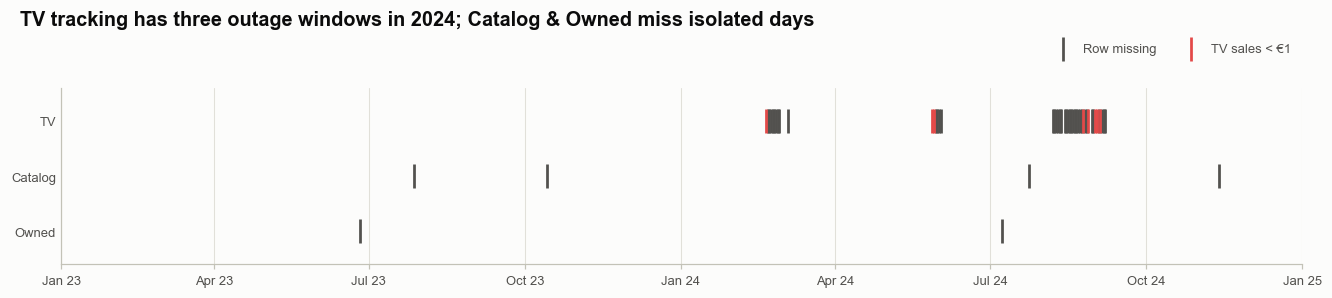

,missing days,est. sales lost (€),est. share of total sales
TV,38,"€181,048",0.031%
Catalog,4,"€438,959",0.076%
Owned,2,"€3,212",0.001%


TV days with sales < €1: 2024-02-20, 2024-05-28, 2024-05-29, 2024-08-25, 2024-08-28, 2024-09-01, 2024-09-02, 2024-09-04


In [7]:
gap_rows = ["TV", "Catalog", "Owned"]
fig, ax = plt.subplots(figsize=(12, 2.6), layout="constrained")
for i, ch in enumerate(gap_rows):
    missing = all_days.difference(raw.loc[raw["channel"] == ch, "date"])
    ax.scatter(missing, [i] * len(missing), marker="|", s=260, color=INK_2, lw=1.8,
               label="Row missing" if i == 0 else None)
tv_zero = raw.loc[(raw["channel"] == "TV") & (raw["sales_by_channel"] < 1), "date"]
ax.scatter(tv_zero, [0] * len(tv_zero), marker="|", s=260, color=NEGATIVE, lw=1.8,
           label="TV sales < €1")
ax.set_yticks(range(len(gap_rows)), gap_rows)
ax.set_ylim(-0.6, len(gap_rows) - 0.4)
ax.set_xlim(all_days[0], all_days[-1])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
date_axis(ax)
ax.legend(loc="upper right", ncol=2, bbox_to_anchor=(1, 1.32))
headline(fig, "TV tracking has three outage windows in 2024; Catalog & Owned miss isolated days")
save(fig, "missing_days")
plt.show()

channel_mean = raw.groupby("channel")["sales_by_channel"].mean()
missing_summary = pd.DataFrame(
    {"missing days": [len(all_days.difference(raw.loc[raw["channel"] == c, "date"])) for c in gap_rows]},
    index=gap_rows,
)
missing_summary["est. sales lost (€)"] = missing_summary["missing days"] * channel_mean[gap_rows]
missing_summary["est. share of total sales"] = (
    missing_summary["est. sales lost (€)"] / raw["sales_by_channel"].sum()
)
display(missing_summary.style.format({"est. sales lost (€)": "€{:,.0f}",
                                      "est. share of total sales": "{:.3%}"}))
print("TV days with sales < €1:", ", ".join(tv_zero.dt.strftime("%Y-%m-%d")))

- **TV** misses 38 days in three windows (late Feb, end of May, Aug–early Sep 2024) and has 8 more days with sales below €1 that sit
  *right next to* those windows — these are tracking outages, not genuine zero demand.
- **Catalog** misses 4 days and **Owned** 2 — isolated gaps.
- Impact on the target is negligible (≈ 0.1 % of total sales in total), so filling missing channel-days with 0 when summing the target is
  safe — but the rows should be flagged.

### 3.4 Value ranges per channel and metric

In [8]:
profile = raw.groupby("channel")[num_cols].describe(percentiles=[0.5]).loc[CHANNELS]
profile = profile.loc[:, (slice(None), ["count", "min", "50%", "max"])]
display(profile.style.format("{:,.0f}", na_rep="–"))

Scale differences are extreme: a catalog send-out costs **€1.0–1.7 M** in one day while PSM spends **~€2.7 K** a day. Impressions range
from a few thousand (Affiliate) to >100 M (Display). Any model must work on transformed / standardised inputs.

### 3.5 Data-quality summary

| # | Issue | Scope | Treatment in preparation |
|---|---|---|---|
| 1 | Rows shuffled, long format | all 8,740 rows | sort, pivot to wide `date × channel` |
| 2 | Missing channel-days | TV 38, Catalog 4, Owned 2 | fill sales with 0 for the target, keep a flag |
| 3 | TV near-zero sales | 8 days | tracking outage — flag (TV is not a feature anyway) |
| 4 | Catalog costs only on send-out days | 700 NaN cost days | NaN → 0 spend (no send-out ≠ missing) |
| 5 | Catalog clicks always 0 | 28 days | drop metric for Catalog |
| 6 | PSM has no impressions | 732 days | use clicks as exposure metric |
| 7 | Organic channels: no costs/clicks/impressions | 5 channels | NaN means *not applicable*, not zero |
| 8 | Single 2025 day | 2025-01-01 | exclude from yearly/monthly comparisons |

## 4. Analytical daily tables

Pivot to one row per day. The dependent variable `total_sales` is the sum of attributed sales over **all 12 channels**.

In [9]:
def to_wide(value, columns):
    return raw.pivot(index="date", columns="channel", values=value).asfreq("D")[columns]


sales_wide = to_wide("sales_by_channel", CHANNELS)   # NaN = missing channel-day
cost_wide = to_wide("costs", PAID)                   # NaN on catalog off-days
impr_wide = to_wide("impressions", PAID)
click_wide = to_wide("clicks", PAID)

sales = sales_wide.fillna(0)
cost = cost_wide.fillna(0)          # no catalog send-out = zero spend
y = sales.sum(axis=1).rename("total_sales")
assert np.isclose(y.sum(), raw["sales_by_channel"].sum())

y_full = y.loc[:"2024-12-31"]       # complete years only, for yearly / monthly views
send_dates = cost.index[cost["Catalog"] > 0]
last_send = pd.Series(cost.index.where(cost["Catalog"] > 0), index=cost.index).ffill()

cal = pd.DataFrame(index=y.index)
cal["year"] = cal.index.year
cal["month"] = cal.index.month
cal["dow"] = cal.index.dayofweek
cal["days_since_catalog"] = (cal.index.to_series() - last_send).dt.days

daily = pd.concat(
    [y, cost.sum(axis=1).rename("total_spend"), cost.add_prefix("cost_"), cal], axis=1
)
print(f"Daily table: {daily.shape[0]} days × {daily.shape[1]} columns")
display(daily.head())

Daily table: 732 days × 13 columns


,total_sales,total_spend,cost_SEA,cost_Catalog,cost_Display,cost_Affiliate,cost_Social Media,cost_Display Network,cost_PSM,year,month,dow,days_since_catalog
date,,,,,,,,,,,,,
2023-01-01,564772.114568,68882.134992,40701.200189,0.0,19928.030984,3256.777190,830.983399,2984.093230,1181.050000,2023,1,6,NaN
2023-01-02,800480.897132,101224.185422,50380.997240,0.0,20795.018740,3945.928628,21418.122400,3042.668416,1641.449998,2023,1,0,NaN
2023-01-03,915709.862692,89813.138563,50127.406243,0.0,27207.311500,5517.745136,2297.147200,2419.678485,2243.849999,2023,1,1,NaN
2023-01-04,870530.852372,93590.044291,54094.849775,0.0,27422.933787,4391.922881,2231.330200,3144.597653,2304.409995,2023,1,2,NaN
2023-01-05,856131.530628,89484.552392,47865.315964,0.0,27731.208208,6231.415498,2514.003400,3085.389326,2057.219996,2023,1,3,NaN


Two helper objects are reused below: the list of **28 catalog send-out dates** and `days_since_catalog` (days since the most recent
send-out), which turns the catalog into an *event study*.

German public holidays (national) come from the `holidays` package; retail events are added manually.

In [10]:
de_holidays = holidays.country_holidays("DE", years=[2023, 2024, 2025], language="en_US")
events = {pd.Timestamp(d): name for d, name in de_holidays.items()}
events.update({
    pd.Timestamp("2023-11-24"): "Black Friday", pd.Timestamp("2023-11-27"): "Cyber Monday",
    pd.Timestamp("2024-11-29"): "Black Friday", pd.Timestamp("2024-12-02"): "Cyber Monday",
    pd.Timestamp("2023-12-24"): "Christmas Eve", pd.Timestamp("2024-12-24"): "Christmas Eve",
    pd.Timestamp("2023-12-31"): "New Year's Eve", pd.Timestamp("2024-12-31"): "New Year's Eve",
})
events = dict(sorted((d, n) for d, n in events.items() if d in y.index))
print(f"{len(events)} calendar events in range")

27 calendar events in range


## 5. Target: total daily sales

### 5.1 Key figures

In [11]:
def target_profile(s):
    return pd.Series({
        "days": len(s), "total": s.sum(), "mean": s.mean(), "median": s.median(),
        "std": s.std(), "min": s.min(), "max": s.max(),
        "coefficient of variation": s.std() / s.mean(),
        "skewness": s.skew(), "excess kurtosis": s.kurt(),
    })


target_kpis = pd.DataFrame({
    "2023": target_profile(y[y.index.year == 2023]),
    "2024": target_profile(y[y.index.year == 2024]),
    "All days": target_profile(y),
})
money = ["total", "mean", "median", "std", "min", "max"]
display(
    target_kpis.style
    .format("€{:,.0f}", subset=pd.IndexSlice[money, :])
    .format("{:,.0f}", subset=pd.IndexSlice[["days"], :])
    .format("{:.2f}", subset=pd.IndexSlice[["coefficient of variation", "skewness", "excess kurtosis"], :])
)
yoy = y[y.index.year == 2024].sum() / y[y.index.year == 2023].sum() - 1
print(f"Total sales 2024 vs 2023: {yoy:+.1%}   (2024 has one extra day: leap year)")

,2023,2024,All days
days,365,366,732
total,"€260,785,035","€314,803,501","€576,298,080"
mean,"€714,480","€860,119","€787,292"
median,"€666,206","€817,610","€736,961"
std,"€271,445","€273,809","€281,843"
min,"€218,492","€290,416","€218,492"
max,"€2,697,881","€2,753,320","€2,753,320"
coefficient of variation,0.38,0.32,0.36
skewness,2.51,1.82,1.95
excess kurtosis,13.08,7.60,8.61


Total sales 2024 vs 2023: +20.7%   (2024 has one extra day: leap year)


### 5.2 Daily sales over time

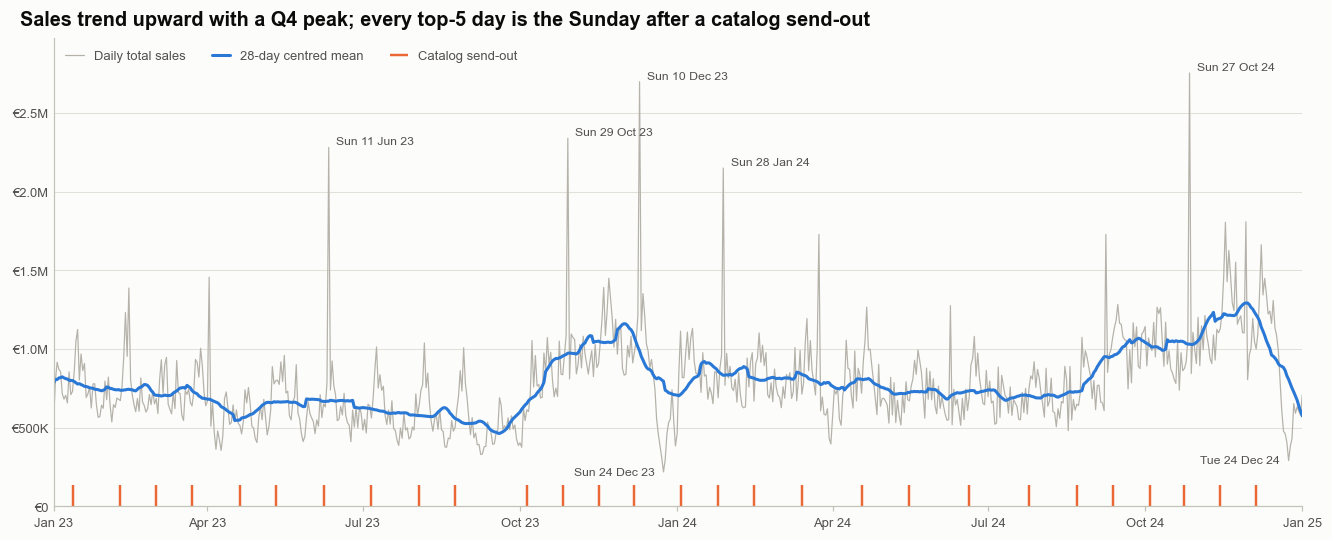

In [12]:
roll = y.rolling(28, center=True, min_periods=14).mean()
fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
ax.plot(y.index, y, color=NEUTRAL, lw=0.8, label="Daily total sales")
ax.plot(roll.index, roll, color=ACCENT, lw=2, label="28-day centred mean")
catalog_rug(ax, send_dates)
for d in y.nlargest(5).index:
    ax.annotate(f"{d:%a %d %b %y}", (d, y[d]), xytext=(5, 2), textcoords="offset points",
                fontsize=8, color=INK_2)
for d in y.nsmallest(2).index:
    ax.annotate(f"{d:%a %d %b %y}", (d, y[d]), xytext=(-6, 0), textcoords="offset points",
                fontsize=8, color=INK_2, ha="right", va="center")
ax.yaxis.set_major_formatter(EUR)
ax.set_ylim(0, y.max() * 1.08)
ax.set_xlim(y.index[0], y.index[-1])
date_axis(ax)
ax.legend(loc="upper left", ncol=3)
headline(fig, "Sales trend upward with a Q4 peak; every top-5 day is the Sunday after a catalog send-out")
save(fig, "target_timeseries")
plt.show()

- A clear **upward level shift** from mid-2023 into 2024, and a **Q4 hump** in both years.
- The series is **spiky**: the five highest days (up to €2.75 M, 3.5× the mean) are all Sundays three days after a catalog send-out (orange
  ticks) — the catalog is the dominant driver of demand peaks (Section 10).
- The lowest days are Christmas (24–25 Dec) — holiday effects must be modelled explicitly.

### 5.3 Distribution

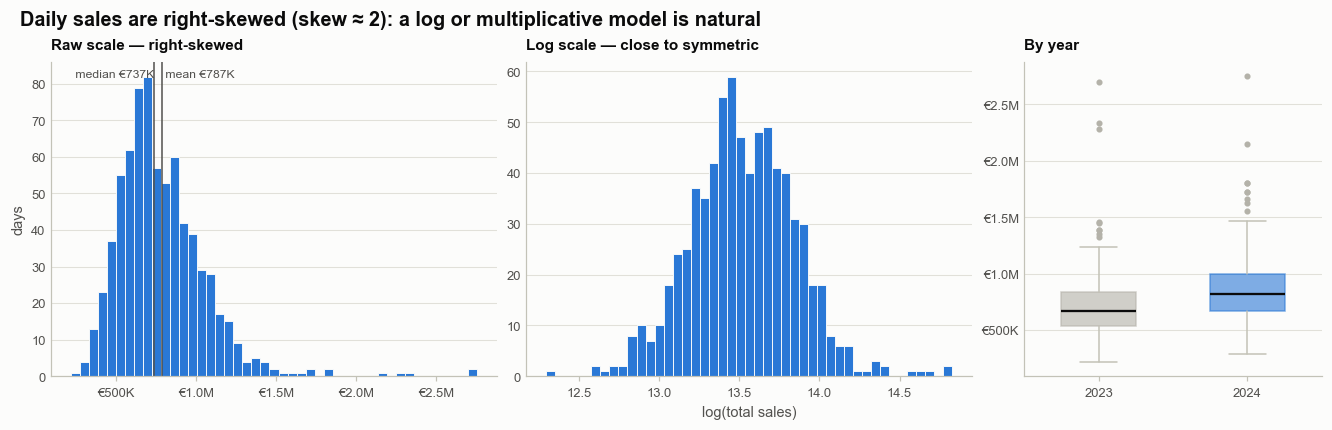

Skewness raw: 1.95 | log: 0.16


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained",
                         gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})
ax = axes[0]
ax.hist(y, bins=45, color=ACCENT, edgecolor=SURFACE, linewidth=0.6)
for value, label in [(y.mean(), "mean"), (y.median(), "median")]:
    ax.axvline(value, color=INK_2, lw=1)
    ax.text(value, ax.get_ylim()[1] * 0.95, f" {label} {compact(value)}", fontsize=8,
            color=INK_2, ha="left" if label == "mean" else "right")
ax.xaxis.set_major_formatter(EUR)
ax.set_title("Raw scale — right-skewed", fontsize=10)
ax.set_ylabel("days")

ax = axes[1]
ax.hist(np.log(y), bins=45, color=ACCENT, edgecolor=SURFACE, linewidth=0.6)
ax.set_title("Log scale — close to symmetric", fontsize=10)
ax.set_xlabel("log(total sales)")

ax = axes[2]
data = [y[y.index.year == yr].values for yr in (2023, 2024)]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, medianprops={"color": INK, "lw": 1.5},
                whiskerprops={"color": AXIS}, capprops={"color": AXIS},
                flierprops={"marker": "o", "markersize": 3, "markerfacecolor": NEUTRAL,
                            "markeredgecolor": NEUTRAL})
for patch, c in zip(bp["boxes"], [NEUTRAL, ACCENT]):
    patch.set(facecolor=c, edgecolor=c, alpha=0.6)
ax.set_xticks([1, 2], ["2023", "2024"])
ax.yaxis.set_major_formatter(EUR)
ax.set_title("By year", fontsize=10)
headline(fig, "Daily sales are right-skewed (skew ≈ 2): a log or multiplicative model is natural")
save(fig, "target_distribution")
plt.show()

print(f"Skewness raw: {y.skew():.2f} | log: {np.log(y).skew():.2f}")

The heavy right tail comes from catalog peaks and Q4. On a log scale the distribution is near-symmetric, which supports
**log-transforming the target** (multiplicative effects: a catalog lifts sales by a *percentage* of the current level) or at least using a
loss that is robust to peaks. Note that the KPI is MAE-based, so a few large misses on peak days weigh heavily.

### 5.4 Year-over-year comparison

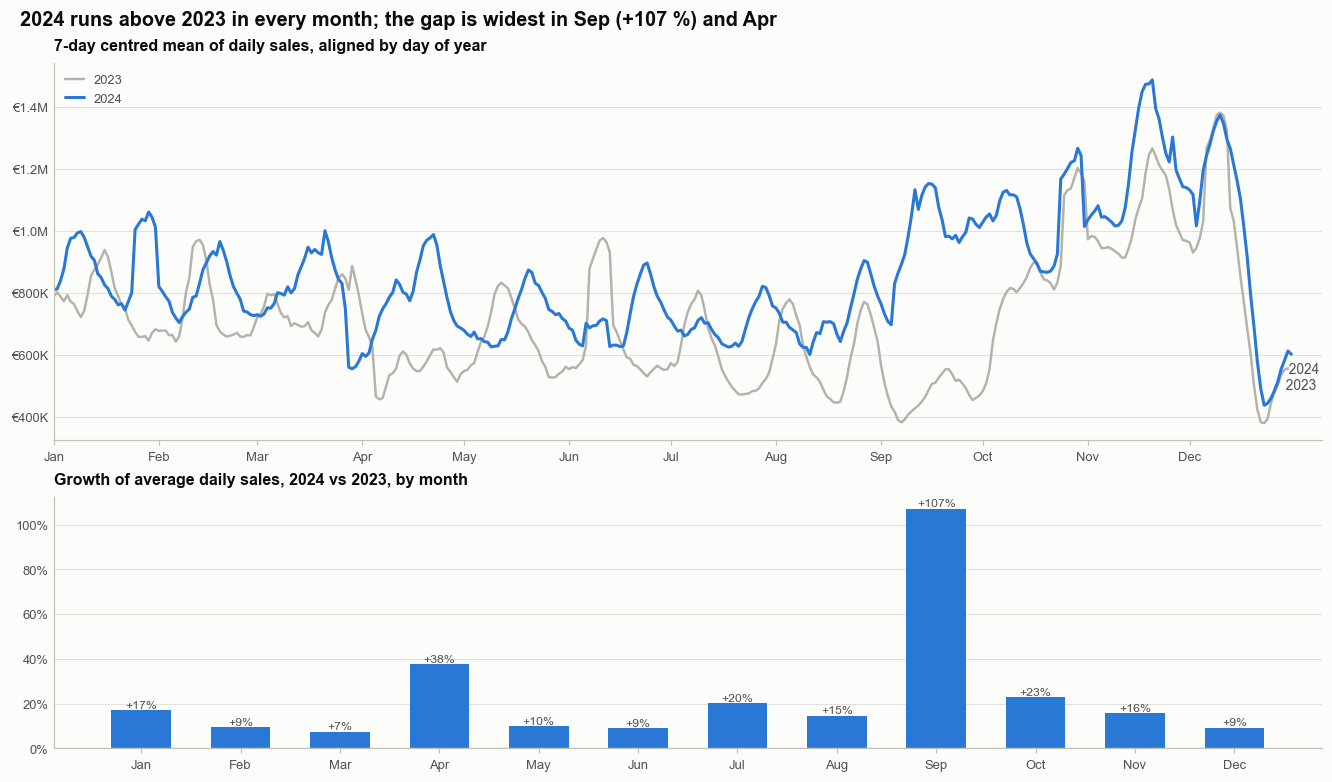

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained",
                         gridspec_kw={"height_ratios": [1.5, 1]})
ax = axes[0]
for yr, color, lw in [(2023, NEUTRAL, 1.6), (2024, ACCENT, 2)]:
    s = y[y.index.year == yr].rolling(7, center=True, min_periods=4).mean()
    ax.plot(s.index.dayofyear, s.values, color=color, lw=lw, label=str(yr))
    ax.text(s.index.dayofyear[-4], s.values[-4], f"  {yr}", color=INK_2, fontsize=9, va="center")
month_starts = pd.date_range("2024-01-01", "2024-12-01", freq="MS")
ax.set_xticks(month_starts.dayofyear, month_starts.strftime("%b"))
ax.set_xlim(1, 375)
ax.yaxis.set_major_formatter(EUR)
ax.set_title("7-day centred mean of daily sales, aligned by day of year")
ax.legend(loc="upper left")

ax = axes[1]
monthly = y_full.resample("MS").mean()
growth = (monthly[monthly.index.year == 2024].values / monthly[monthly.index.year == 2023].values) - 1
ax.bar(range(12), growth, color=[ACCENT if g >= 0 else NEGATIVE for g in growth], width=0.6)
for i, g in enumerate(growth):
    ax.text(i, g, f"{g:+.0%}", ha="center", va="bottom" if g >= 0 else "top", fontsize=8, color=INK_2)
ax.set_xticks(range(12), month_starts.strftime("%b"))
ax.yaxis.set_major_formatter(PCT)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_title("Growth of average daily sales, 2024 vs 2023, by month")
headline(fig, "2024 runs above 2023 in every month; the gap is widest in Sep (+107 %) and Apr")
save(fig, "target_yoy")
plt.show()

- 2024 is above 2023 **in every month** (+20.7 % overall), so the model needs a **trend / level** component — a model trained on the past
  must be able to extrapolate a higher level into the test period (this is why tree models struggle here, see PLAN §2.6).
- The **September** gap (+107 %) is not organic growth: in Sept 2023 no catalog was sent for 42 days, while 2024 had a send-out on 12 Sep
  *and* the Social Media regime change (Section 8.3). Month-level growth is partly *marketing-driven*.

### 5.5 Weekly and monthly seasonality

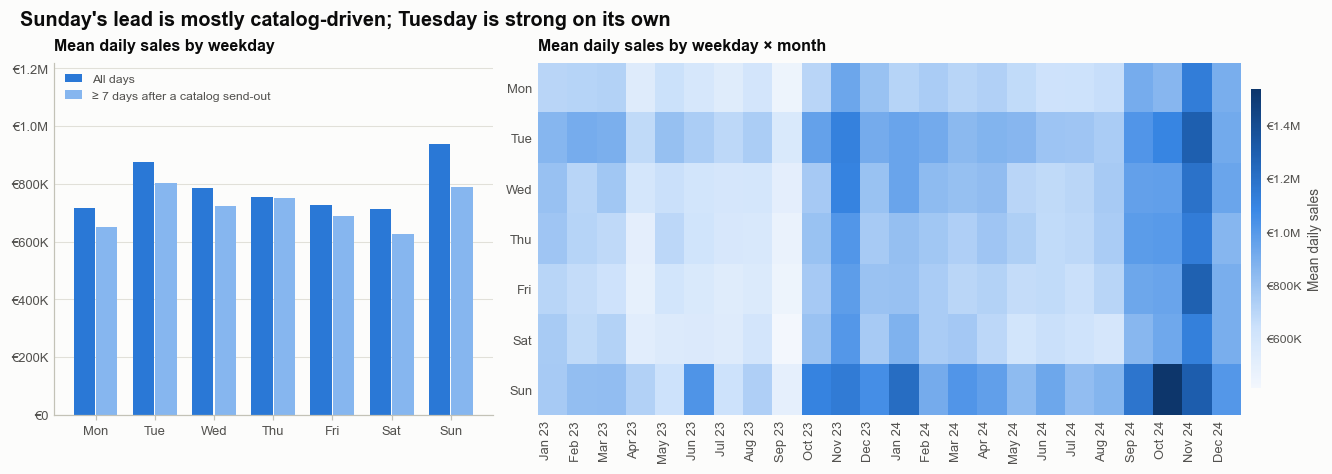

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
all days,"€716,408","€874,688","€784,307","€755,221","€726,817","€714,110","€937,918"
≥7 days after send-out,"€650,250","€803,974","€723,342","€749,990","€686,972","€625,986","€789,227"


In [15]:
clean = cal["days_since_catalog"] >= 7
weekday_all = y.groupby(cal["dow"]).mean()
weekday_clean = y[clean].groupby(cal.loc[clean, "dow"]).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
x = np.arange(7)
ax.bar(x - 0.19, weekday_all.values, width=0.36, color=ACCENT, label="All days")
ax.bar(x + 0.19, weekday_clean.values, width=0.36, color=LIGHT_ACCENT,
       label="≥ 7 days after a catalog send-out")
ax.set_xticks(x, DOW)
ax.yaxis.set_major_formatter(EUR)
ax.set_ylim(0, weekday_all.max() * 1.3)
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Mean daily sales by weekday")

ax = axes[1]
wk_month = (
    y_full.groupby([cal["dow"], y_full.index.to_period("M")]).mean().unstack()
)
wk_month.index = DOW
wk_month.columns = [p.strftime("%b %y") for p in wk_month.columns]
heatmap(ax, wk_month, cmap=SEQ, annot=False, cbar_label="Mean daily sales", xrot=90, cbar_fmt=EUR)
ax.set_title("Mean daily sales by weekday × month")
headline(fig, "Sunday's lead is mostly catalog-driven; Tuesday is strong on its own")
save(fig, "target_seasonality")
plt.show()

display(pd.DataFrame({"all days": weekday_all, "≥7 days after send-out": weekday_clean},
                     ).set_axis(DOW).T.style.format("€{:,.0f}"))

- On all days Sunday looks strongest (≈ €938 K) — but on days **without recent catalog influence** Sunday drops to ≈ €789 K, below Tuesday
  (≈ €804 K). The "Sunday effect" is largely the catalog's +3-day peak (send-outs are almost always on Thursdays), so a weekday dummy and
  a catalog-lag feature are **confounded** — they must be estimated jointly.
- **Tuesday** is strong independently of the catalog (plausibly Tchibo's weekly product-range change — a hypothesis to confirm with the
  business). Monday and Saturday are the weakest days.
- The heatmap shows the yearly pattern: weak spring/summer 2023 and Sep 2023, a strong Q4, and a higher plateau through 2024.

### 5.6 Decomposition (STL)

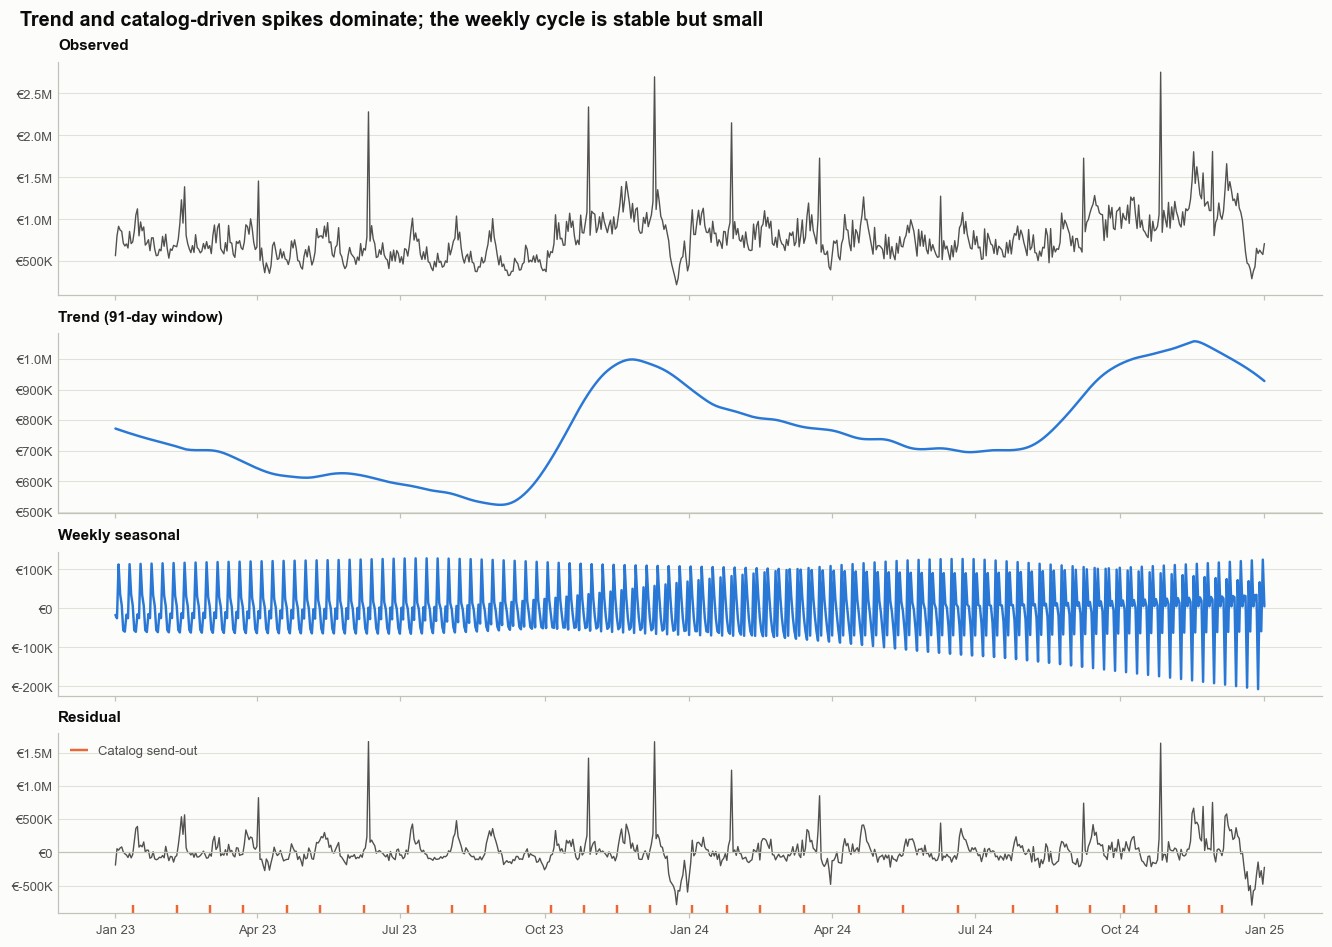

Strength of trend: 0.35 | strength of weekly seasonality: 0.09 (0 = none, 1 = all)
Variance of each component relative to the variance of sales: trend 28%, weekly seasonal 6%, residual 61%
Of the 15 largest STL residuals, 67% fall 0–6 days after a send-out.


In [16]:
stl = STL(y, period=7, seasonal=53, trend=91, robust=True).fit()
strength_trend = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
strength_weekly = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))

fig, axes = plt.subplots(4, 1, figsize=(12, 8.5), sharex=True, layout="constrained",
                         gridspec_kw={"height_ratios": [1.3, 1, 0.8, 1]})
parts = [("Observed", y, INK_2), ("Trend (91-day window)", stl.trend, ACCENT),
         ("Weekly seasonal", stl.seasonal, ACCENT), ("Residual", stl.resid, INK_2)]
for ax, (title, s, color) in zip(axes, parts):
    ax.plot(s.index, s.values, color=color, lw=0.9 if title in ("Observed", "Residual") else 1.6)
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_major_formatter(EUR)
catalog_rug(axes[3], send_dates)
axes[3].axhline(0, color=AXIS, lw=0.8)
axes[3].legend(loc="upper left")
date_axis(axes[3])
headline(fig, "Trend and catalog-driven spikes dominate; the weekly cycle is stable but small")
save(fig, "target_stl")
plt.show()

top_resid = stl.resid.nlargest(15).index
share_after_catalog = (cal.loc[top_resid, "days_since_catalog"] <= 6).mean()
variance_share = pd.Series({"trend": stl.trend.var(), "weekly seasonal": stl.seasonal.var(),
                            "residual": stl.resid.var()}) / y.var()
print(f"Strength of trend: {strength_trend:.2f} | strength of weekly seasonality: {strength_weekly:.2f} (0 = none, 1 = all)")
print("Variance of each component relative to the variance of sales:",
      ", ".join(f"{k} {v:.0%}" for k, v in variance_share.items()))
print(f"Of the 15 largest STL residuals, {share_after_catalog:.0%} fall 0–6 days after a send-out.")

STL (robust, weekly period, 91-day trend window) separates a smooth trend — a summer-2023 low, a Q4-2023 hump, a higher 2024 plateau and
a second Q4 hump — from a stable weekly cycle. The trend carries ~28 % of the variance of daily sales and the weekly cycle only ~6 %;
the remaining **~61 % sits in the "residual"**, and two-thirds of its largest spikes fall 0–6 days after a send-out. In other words the
residual is largely a **marketing signal (catalog), not noise** — exactly what the media features must explain. The weekly swing also
grows as the level rises in late 2024 — another hint that effects are multiplicative (log model). With only two years, a
separate yearly component cannot be estimated robustly (two cycles); yearly seasonality will need a low-order Fourier representation
and holiday dummies.

### 5.7 Stationarity & autocorrelation

In [17]:
def stationarity(s, name):
    adf_stat, adf_p, *_ = adfuller(s.dropna(), autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(s.dropna(), regression="c", nlags="auto")
    verdict = "stationary" if adf_p < 0.05 and kpss_p > 0.05 else "non-stationary / ambiguous"
    return {"series": name, "ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat,
            "KPSS p": kpss_p, "verdict": verdict}


log_y = np.log(y)
tests = pd.DataFrame([
    stationarity(y, "total sales"),
    stationarity(log_y, "log total sales"),
    stationarity(log_y.diff(7), "weekly difference of log sales"),
]).set_index("series")
display(tests.style.format({"ADF stat": "{:.2f}", "ADF p": "{:.3f}", "KPSS stat": "{:.2f}",
                            "KPSS p": "{:.3f}"}))

,ADF stat,ADF p,KPSS stat,KPSS p,verdict
series,,,,,
total sales,-2.32,0.165,1.20,0.010,non-stationary / ambiguous
log total sales,-2.35,0.155,1.12,0.010,non-stationary / ambiguous
weekly difference of log sales,-8.87,0.000,0.02,0.100,stationary


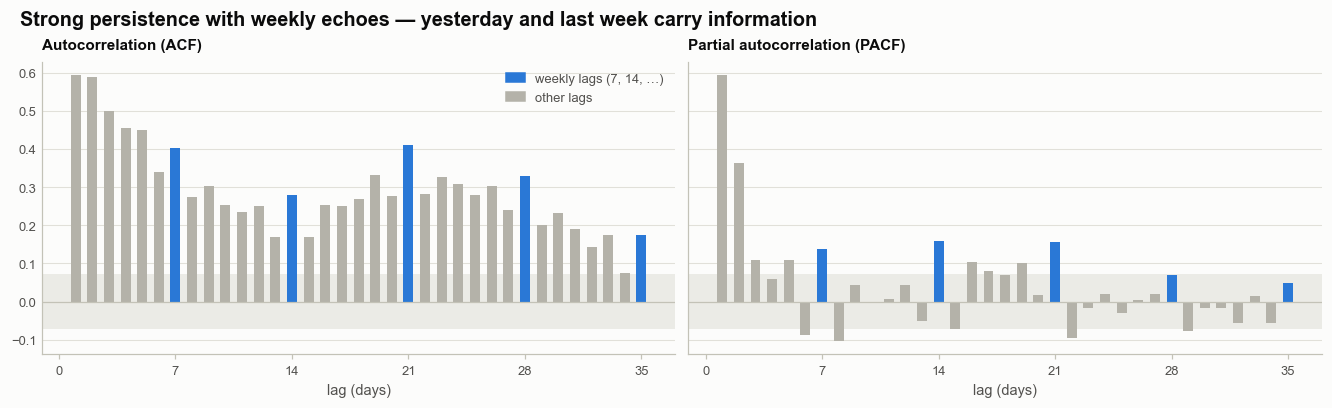

In [18]:
nlags = 35
acf_vals = acf(y, nlags=nlags)
pacf_vals = pacf(y, nlags=nlags, method="ywm")
band = 1.96 / np.sqrt(len(y))
weekly = np.arange(nlags + 1) % 7 == 0

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained", sharey=True)
for ax, vals, title in [(axes[0], acf_vals, "Autocorrelation (ACF)"),
                        (axes[1], pacf_vals, "Partial autocorrelation (PACF)")]:
    lags = np.arange(1, nlags + 1)
    colors = [ACCENT if w else NEUTRAL for w in weekly[1:]]
    ax.bar(lags, vals[1:], color=colors, width=0.6, zorder=2)
    ax.axhspan(-band, band, color=GRID, alpha=0.6, lw=0, zorder=1)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.set_xticks(range(0, nlags + 1, 7))
    ax.set_xlabel("lag (days)")
    ax.set_title(title, fontsize=10)
axes[0].legend(handles=[Patch(color=ACCENT, label="weekly lags (7, 14, …)"),
                        Patch(color=NEUTRAL, label="other lags")], loc="upper right")
headline(fig, "Strong persistence with weekly echoes — yesterday and last week carry information")
save(fig, "target_acf")
plt.show()

- Both ADF (cannot reject a unit root) and KPSS (rejects stationarity) agree that **raw sales are non-stationary** — driven by the trend
  and level shift. After a weekly log-difference the series becomes stationary.
- ACF decays slowly with **peaks at multiples of 7**; PACF shows strong lag-1 and weekly terms. Autoregressive features (lag 1, lag 7)
  would help a short-horizon forecast, but they are only legitimate if the forecast horizon allows them — the headline model should be
  driven by budget and calendar (PLAN §5, model M1 vs M4).
- For regression with time-series errors: expect **autocorrelated residuals** → use time-based CV and HAC standard errors for inference.

### 5.8 Holidays & retail events

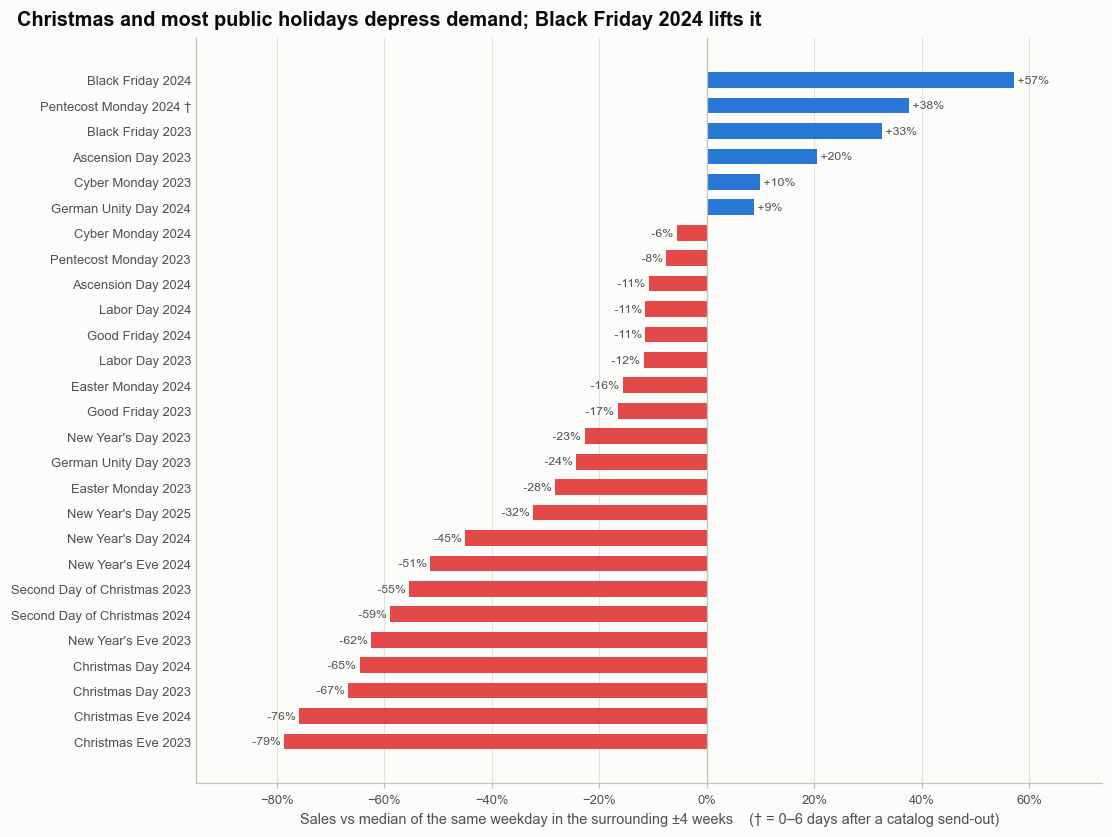

In [19]:
def same_weekday_baseline(s, day, weeks=4):
    refs = [day + pd.Timedelta(weeks=k) for k in range(-weeks, weeks + 1) if k != 0]
    refs = [d for d in refs if d in s.index and d not in events]
    return s.loc[refs].median()


event_table = pd.DataFrame([
    {
        "date": d, "event": name, "weekday": d.strftime("%a"), "sales": y[d],
        "baseline (same weekday ±4 wks)": same_weekday_baseline(y, d),
        "days since catalog": cal.loc[d, "days_since_catalog"],
    }
    for d, name in events.items()
]).set_index("date")
event_table["lift vs baseline"] = event_table["sales"] / event_table["baseline (same weekday ±4 wks)"] - 1

plot_df = event_table.assign(
    label=[f"{n} {d.year}{' †' if 0 <= c <= 6 else ''}"
           for d, n, c in zip(event_table.index, event_table["event"], event_table["days since catalog"])]
).set_index("label")["lift vs baseline"]

fig, ax = plt.subplots(figsize=(10, 7.5), layout="constrained")
s = plot_df.sort_values()
ax.barh(s.index, s.values, color=[ACCENT if v >= 0 else NEGATIVE for v in s.values], height=0.62)
for i, v in enumerate(s.values):
    ax.text(v, i, f" {v:+.0%} ", va="center", ha="left" if v >= 0 else "right", fontsize=8, color=INK_2)
ax.axvline(0, color=AXIS, lw=0.8)
ax.xaxis.set_major_formatter(PCT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.margins(x=0.12)
ax.set_xlabel("Sales vs median of the same weekday in the surrounding ±4 weeks    († = 0–6 days after a catalog send-out)")
headline(fig, "Christmas and most public holidays depress demand; Black Friday 2024 lifts it")
save(fig, "events_lift")
plt.show()

- The **Christmas window** is the deepest trough: Christmas Eve −76 % / −79 %, Christmas Day −65 % / −67 %, Boxing Day and New Year's
  Eve −51 % to −62 %. Easter, New Year's Day and most other public holidays are −10 % to −45 %: for this retailer, holidays mean *lower*
  demand — they need dedicated dummies (a whole 23–31 Dec window rather than single days).
- **Black Friday** lifts demand in both years (+33 % in 2023, +57 % in 2024); Cyber Monday shows no consistent effect.
- Events marked † coincide with a catalog response window — e.g. Pentecost Monday 2024 (+38 %) is the catalog, not the holiday. Only
  two occurrences per event exist, so event effects will be estimated with high uncertainty.

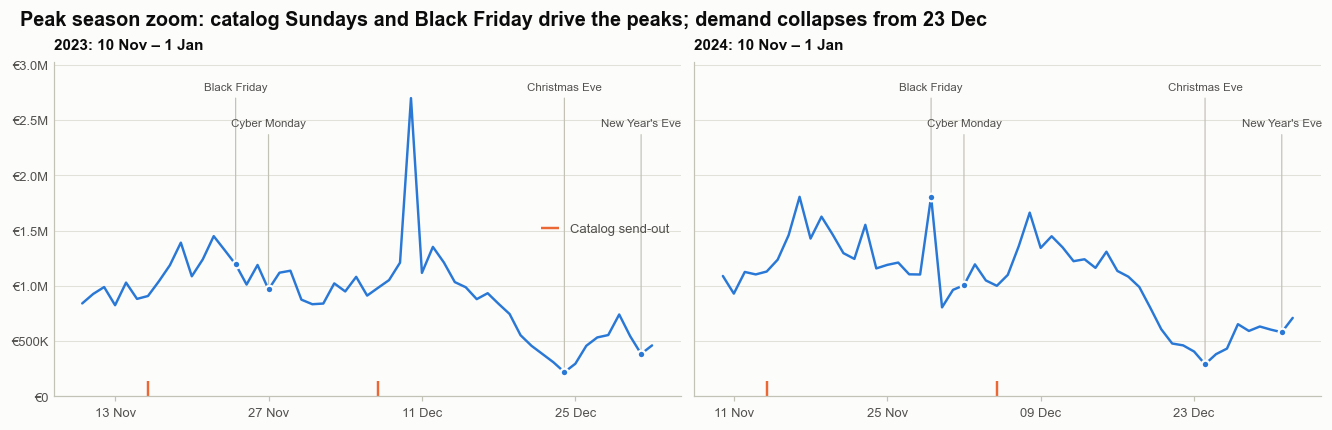

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained", sharey=True)
for ax, yr in zip(axes, (2023, 2024)):
    window = y.loc[f"{yr}-11-10":f"{yr + 1}-01-01"]
    ax.plot(window.index, window.values, color=ACCENT, lw=1.6)
    catalog_rug(ax, send_dates[(send_dates >= window.index[0]) & (send_dates <= window.index[-1])])
    shown = [(d, n) for d, n in events.items() if window.index[0] <= d <= window.index[-1]
             and n in ("Black Friday", "Cyber Monday", "Christmas Eve", "New Year's Eve")]
    for k, (d, name) in enumerate(shown):
        label_y = y.max() * (1.0 if k % 2 == 0 else 0.88)
        ax.annotate(name, xy=(d, y[d]), xytext=(d, label_y), ha="center", va="bottom", fontsize=7.5,
                    color=INK_2, arrowprops={"arrowstyle": "-", "color": AXIS, "lw": 0.8})
        ax.plot(d, y[d], "o", color=ACCENT, ms=5, mec=SURFACE, mew=1.5, zorder=3)
    ax.set_ylim(0, y.max() * 1.1)
    ax.set_title(f"{yr}: 10 Nov – 1 Jan", fontsize=10)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.yaxis.set_major_formatter(EUR)
axes[0].legend(loc="center right")
headline(fig, "Peak season zoom: catalog Sundays and Black Friday drive the peaks; demand collapses from 23 Dec")
save(fig, "peak_season")
plt.show()

### 5.9 Extreme days

In [21]:
def describe_days(idx):
    return pd.DataFrame({
        "total sales": y[idx].values, "weekday": idx.strftime("%a"),
        "days since catalog": cal.loc[idx, "days_since_catalog"].astype("Int64").values,
        "event": [events.get(d, "") for d in idx],
    }, index=idx.strftime("%Y-%m-%d"))


top = describe_days(y.nlargest(10).index)
bottom = describe_days(y.nsmallest(10).index)
display(top.style.format({"total sales": "€{:,.0f}"}).set_caption("10 highest days"))
display(bottom.style.format({"total sales": "€{:,.0f}"}).set_caption("10 lowest days"))

,total sales,weekday,days since catalog,event
date,,,,
2024-10-27,"€2,753,320",Sun,3,
2023-12-10,"€2,697,881",Sun,3,
2023-10-29,"€2,338,957",Sun,3,
2023-06-11,"€2,280,239",Sun,3,
2024-01-28,"€2,149,374",Sun,3,
2024-11-29,"€1,807,525",Fri,15,Black Friday
2024-11-17,"€1,804,729",Sun,3,
2024-03-24,"€1,728,211",Sun,10,
2024-09-08,"€1,728,109",Sun,17,


,total sales,weekday,days since catalog,event
date,,,,
2023-12-24,"€218,492",Sun,17,Christmas Eve
2024-12-24,"€290,416",Tue,19,Christmas Eve
2023-12-25,"€294,851",Mon,18,Christmas Day
2023-12-23,"€307,870",Sat,16,
2023-09-08,"€328,837",Fri,15,
2023-09-09,"€332,709",Sat,16,
2023-04-09,"€355,092",Sun,17,
2023-04-06,"€362,551",Thu,14,
2023-10-02,"€374,774",Mon,39,


**Peaks are marketing; troughs are calendar.** 7 of the 10 highest days are exactly 3 days after a catalog send-out (the Sunday), one is
Black Friday 2024 and one (Sun 24 Mar 2024) sits in the catalog's second-week echo. Only **Sun 8 Sep 2024** (17 days after a send-out) is
explained by neither — its lift is spread across SEA, Direct Type-in, Social and Display, which points to a promotion or event we cannot
see in the data. The lowest
days are the Christmas window, the catalog-free September 2023 and the Easter weekend 2023. These outliers are mostly *explainable*
and should be modelled, not removed.

## 6. Channel landscape — attributed sales

`sales_by_channel` is *attributed* demand (most likely last-touch). It tells us where sales were credited, **not** what caused them —
but it is the best view of the channel mix and how it moves.

### 6.1 Channel summary

In [22]:
by_year = sales.groupby(sales.index.year).sum()
channel_summary = pd.DataFrame({
    "has costs": [c in PAID for c in CHANNELS],
    "total sales": sales.sum(),
    "share": sales.sum() / sales.sum().sum(),
    "mean / day": sales_wide.mean(),
    "CV (daily)": sales_wide.std() / sales_wide.mean(),
    "YoY 2024 vs 2023": by_year.loc[2024] / by_year.loc[2023] - 1,
    "missing days": sales_wide.isna().sum(),
}).sort_values("share", ascending=False)
display(
    channel_summary.style
    .format({"total sales": "€{:,.0f}", "share": "{:.1%}", "mean / day": "€{:,.0f}",
             "CV (daily)": "{:.2f}", "YoY 2024 vs 2023": "{:+.0%}"})
    .bar(subset=["share"], color=LIGHT_ACCENT, vmin=0)
)
paid_share = channel_summary.loc[PAID, "share"].sum()
print(f"Sales attributed to channels with cost data: {paid_share:.1%}")

,has costs,total sales,share,mean / day,CV (daily),YoY 2024 vs 2023,missing days
channel,,,,,,,
SEA,True,"€151,349,850",26.3%,"€206,762",0.35,+29%,0
Direct Type-in,False,"€120,871,667",21.0%,"€165,125",0.33,+17%,0
SEO,False,"€80,960,365",14.0%,"€110,602",0.30,+1%,0
Catalog,True,"€79,890,614",13.9%,"€109,740",0.98,+3%,4
Display,True,"€64,781,110",11.2%,"€88,499",0.33,+36%,0
Affiliate,True,"€39,674,757",6.9%,"€54,200",0.43,+9%,0
Display Network,True,"€14,625,783",2.5%,"€19,981",0.38,+52%,0
Social Media,True,"€11,488,738",2.0%,"€15,695",1.60,+453%,0
PSM,True,"€6,500,012",1.1%,"€8,880",0.41,+13%,0


Sales attributed to channels with cost data: 63.9%


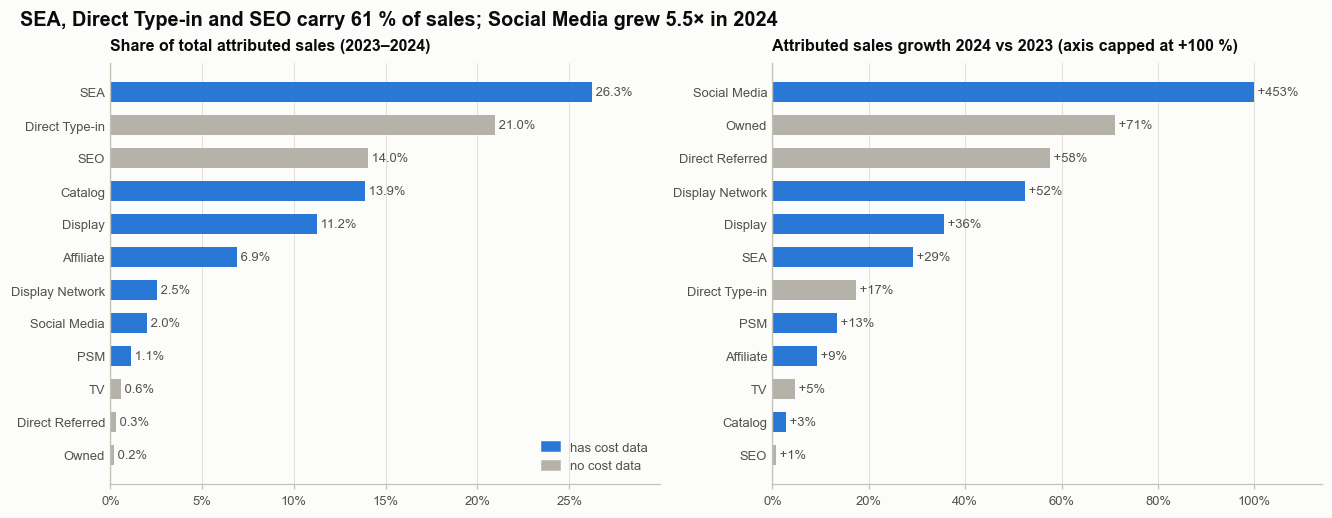

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
ranked_bars(axes[0], channel_summary["share"],
            color={c: (ACCENT if c in PAID else NEUTRAL) for c in CHANNELS}, fmt="{:.1%}")
axes[0].xaxis.set_major_formatter(PCT)
axes[0].set_title("Share of total attributed sales (2023–2024)")
axes[0].legend(handles=[Patch(color=ACCENT, label="has cost data"),
                        Patch(color=NEUTRAL, label="no cost data")], loc="lower right")

growth = channel_summary["YoY 2024 vs 2023"]
ranked_bars(axes[1], growth.clip(upper=1.0),
            color={c: (ACCENT if c in PAID else NEUTRAL) for c in CHANNELS},
            labels=growth.map("{:+.0%}".format))
axes[1].xaxis.set_major_formatter(PCT)
axes[1].set_title("Attributed sales growth 2024 vs 2023 (axis capped at +100 %)")
headline(fig, "SEA, Direct Type-in and SEO carry 61 % of sales; Social Media grew 5.5× in 2024")
save(fig, "channel_share_growth")
plt.show()

- Three channels — **SEA, Direct Type-in and SEO** — account for ~61 % of attributed sales. Channels with cost data account for **~64 %**;
  the remaining ~36 % (organic + TV + owned) are part of the target but cannot be steered by budget → they form the model's *baseline*.
- **Social Media** is the outlier: +453 % attributed sales in 2024. **Catalog** attributed sales are flat (+3 %) while catalog spend fell
  (−11 %, Section 7).

### 6.2 Channel mix over time

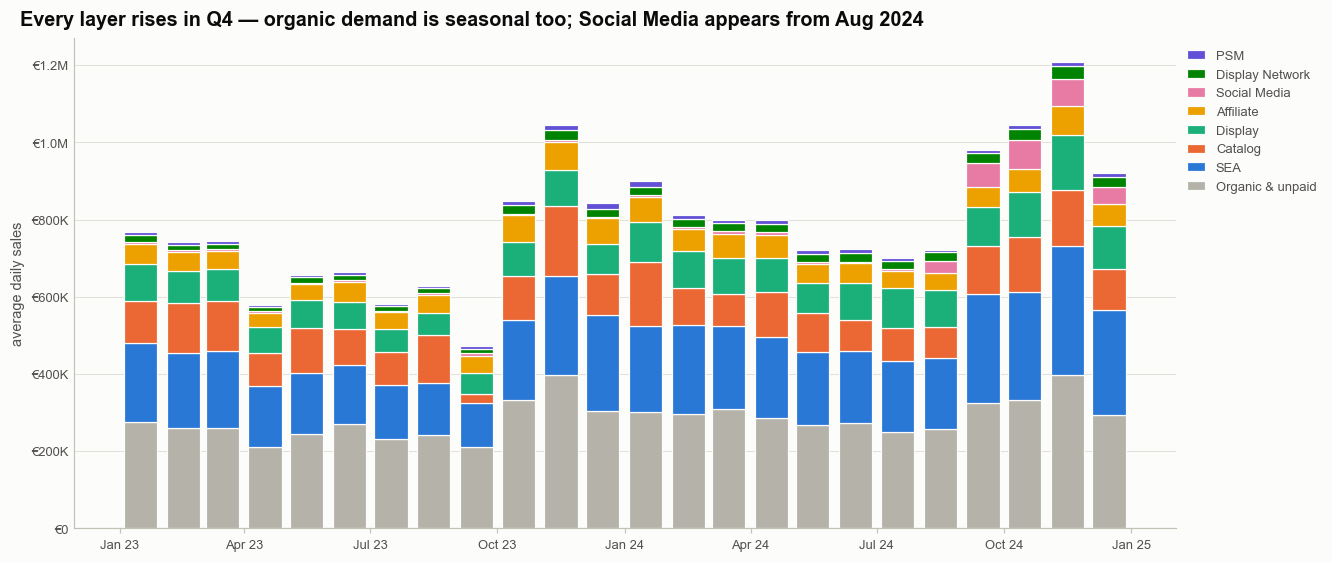

date,2023,2024
channel,,
Organic & unpaid,37.8%,34.7%
SEA,25.3%,27.1%
Catalog,15.1%,12.9%
Display,10.5%,11.8%
Affiliate,7.3%,6.6%
Social Media,0.7%,3.1%
Display Network,2.2%,2.8%
PSM,1.2%,1.1%


In [24]:
mix = sales.loc[:"2024-12-31"].copy()
mix[ORGANIC] = mix[UNPAID].sum(axis=1)
stack_order = [ORGANIC] + PAID
monthly_mix = mix[stack_order].resample("MS").mean()

fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
bottom = np.zeros(len(monthly_mix))
mid_month = monthly_mix.index + pd.Timedelta(days=15)
for col in stack_order:
    ax.bar(mid_month, monthly_mix[col], bottom=bottom, width=24, color=COLOR[col],
           edgecolor=SURFACE, linewidth=0.8, label=col)
    bottom += monthly_mix[col].values
ax.yaxis.set_major_formatter(EUR)
ax.set_ylabel("average daily sales")
date_axis(ax, months=(1, 4, 7, 10))
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.0, 1.0))
headline(fig, "Every layer rises in Q4 — organic demand is seasonal too; Social Media appears from Aug 2024")
save(fig, "channel_mix_monthly")
plt.show()

share_by_year = mix[stack_order].groupby(mix.index.year).sum()
share_by_year = share_by_year.div(share_by_year.sum(axis=1), axis=0).T
display(share_by_year.style.format("{:.1%}").set_caption("Share of attributed sales by year"))

The organic & unpaid block (Direct Type-in, SEO, TV, Direct Referred, Owned) is the largest layer (35–38 % of sales) — in MMM terms it is
part of the **base demand**. It is *not* flat: it also jumps in Oct–Nov and dips in Sep 2023, i.e. organic demand follows the same
season and catalog rhythm as paid channels. Catalog's share fell from 15.1 % to 12.9 % (fewer copies), and Social Media's layer appears
from August 2024.

### 6.3 Each channel's daily sales (7-day mean)

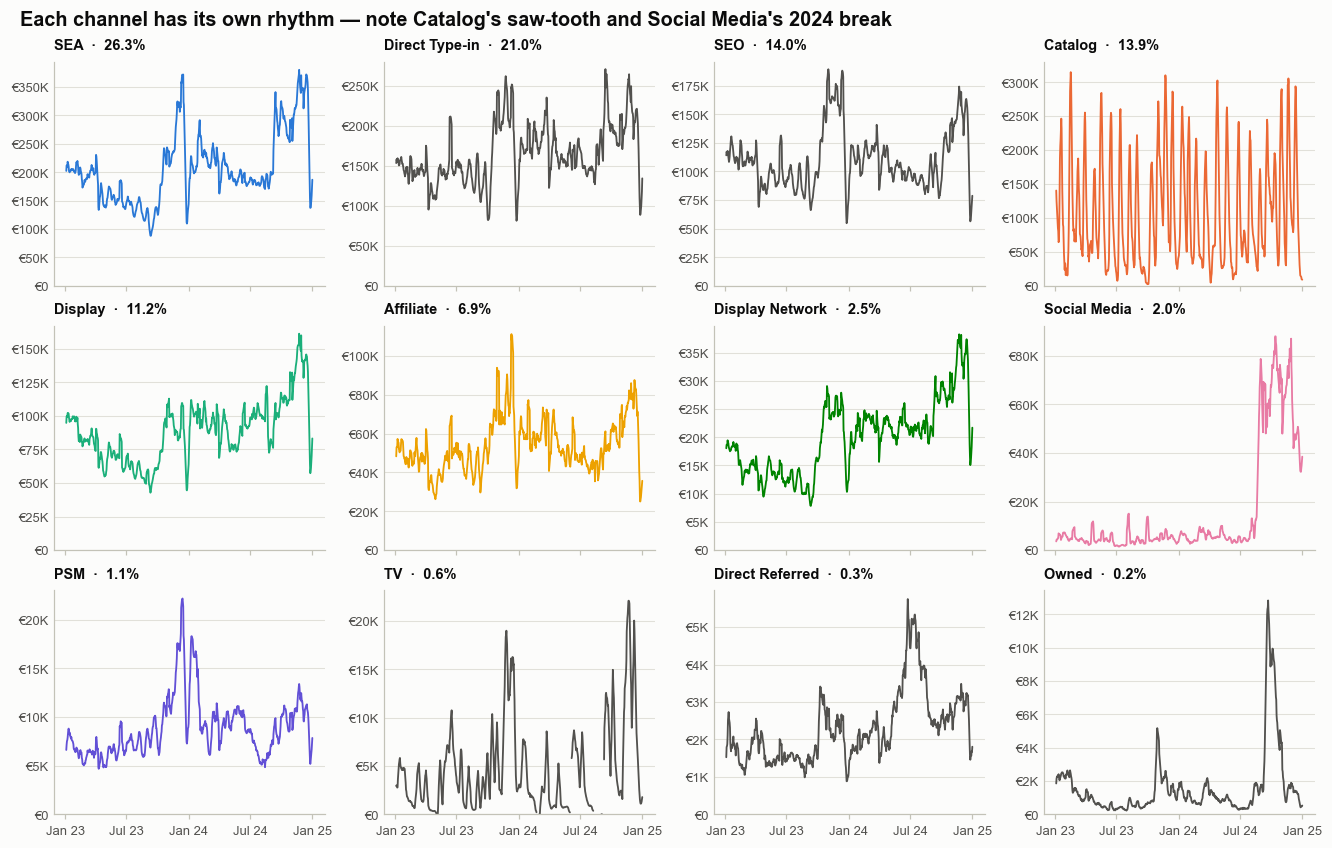

In [25]:
rolled = sales_wide.rolling(7, min_periods=4).mean()
fig, axes = plt.subplots(3, 4, figsize=(12, 7.6), sharex=True, layout="constrained")
for ax, ch in zip(axes.flat, channel_summary.index):
    ax.plot(rolled.index, rolled[ch], color=COLOR[ch] if ch in PAID else INK_2, lw=1.2)
    ax.set_title(f"{ch}  ·  {channel_summary.loc[ch, 'share']:.1%}", fontsize=9.5)
    ax.yaxis.set_major_formatter(EUR)
    ax.set_ylim(bottom=0)
    date_axis(ax, months=(1, 7))
headline(fig, "Each channel has its own rhythm — note Catalog's saw-tooth and Social Media's 2024 break")
save(fig, "channel_small_multiples")
plt.show()

- **Catalog** attributed sales form a saw-tooth that resets with every send-out — the visual signature of a delayed, decaying response.
- **Social Media** shows a **structural break in August 2024**; SEA, Display, Display Network and PSM all dip in summer 2023 and peak in
  Q4 of both years — the same seasonal shape as total sales.
- **TV** is small and noisy with visible outage gaps; **Owned / Direct Referred** are tiny.

### 6.4 Weekday profile by channel

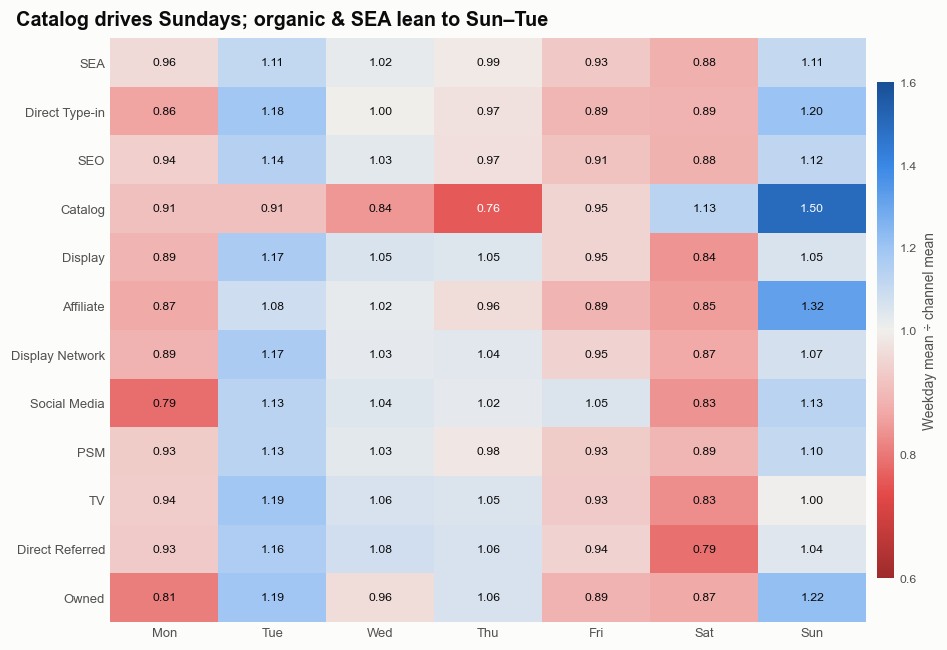

In [26]:
wk_idx = sales_wide.groupby(sales_wide.index.dayofweek).mean() / sales_wide.mean()
wk_idx.index = DOW
wk_idx = wk_idx.T.loc[channel_summary.index]

fig, ax = plt.subplots(figsize=(8.5, 5.8), layout="constrained")
heatmap(ax, wk_idx, cmap=DIV, norm=TwoSlopeNorm(vcenter=1.0, vmin=0.6, vmax=1.6),
        fmt="{:.2f}", cbar_label="Weekday mean ÷ channel mean")
headline(fig, "Catalog drives Sundays; organic & SEA lean to Sun–Tue")
save(fig, "channel_weekday_index")
plt.show()

An index of 1.00 means an average day for that channel. **Catalog** sales are concentrated on **Sunday (1.50×)** and Saturday — 2–3 days
after the Thursday send-out — and Sunday is also high for Affiliate (1.32×), Owned, Direct Type-in and SEO (the catalog halo). Almost
every channel is high on **Tuesday (1.08–1.19×)** and low on **Saturday**, i.e. the Tuesday peak is a *demand* pattern shared by all
channels, not one channel's.

## 7. Marketing investment — costs

### 7.1 Spend summary

In [27]:
spend_by_year = cost.groupby(cost.index.year).sum()
active = cost.where(cost > 0)
spend_summary = pd.DataFrame({
    "spend 2023": spend_by_year.loc[2023],
    "spend 2024": spend_by_year.loc[2024],
    "spend YoY": spend_by_year.loc[2024] / spend_by_year.loc[2023] - 1,
    "sales YoY": by_year.loc[2024, PAID] / by_year.loc[2023, PAID] - 1,
    "share of spend": cost.sum() / cost.sum().sum(),
    "active days": (cost > 0).sum(),
    "mean / active day": active.mean(),
    "CV (active days)": active.std() / active.mean(),
    "max day": cost.max(),
    "max date": cost.idxmax().dt.date,
    "attributed ROAS": sales[PAID].sum() / cost.sum(),
}).sort_values("share of spend", ascending=False)
display(
    spend_summary.style.format({
        "spend 2023": "€{:,.0f}", "spend 2024": "€{:,.0f}", "spend YoY": "{:+.0%}",
        "sales YoY": "{:+.0%}", "share of spend": "{:.1%}", "active days": "{:,.0f}",
        "mean / active day": "€{:,.0f}", "CV (active days)": "{:.2f}", "max day": "€{:,.0f}",
        "attributed ROAS": "{:.2f}",
    })
)
total_spend_year = spend_by_year.sum(axis=1)
print(f"Total spend 2023 €{total_spend_year[2023]:,.0f} → 2024 €{total_spend_year[2024]:,.0f} "
      f"({total_spend_year[2024] / total_spend_year[2023] - 1:+.1%}); "
      f"total sales {yoy:+.1%}")
print(f"Marketing cost ratio (spend / total sales): 2023 {total_spend_year[2023] / y[y.index.year == 2023].sum():.1%}, "
      f"2024 {total_spend_year[2024] / y[y.index.year == 2024].sum():.1%}")

,spend 2023,spend 2024,spend YoY,sales YoY,share of spend,active days,mean / active day,CV (active days),max day,max date,attributed ROAS
channel,,,,,,,,,,,
Catalog,"€20,359,517","€18,197,781",-11%,+3%,30.5%,28,"€1,377,046",0.13,"€1,702,133",2023-02-09,2.07
SEA,"€17,409,657","€21,046,212",+21%,+29%,30.4%,732,"€52,608",0.36,"€134,199",2023-12-10,3.93
Display,"€13,986,283","€15,805,176",+13%,+36%,23.5%,732,"€40,717",0.39,"€112,223",2024-03-24,2.17
Social Media,"€3,377,713","€5,437,476",+61%,+453%,7.0%,732,"€12,054",1.14,"€160,307",2024-10-07,1.30
Affiliate,"€1,713,267","€3,116,769",+82%,+9%,3.8%,732,"€6,604",0.75,"€62,275",2024-10-27,8.21
Display Network,"€1,791,686","€2,294,805",+28%,+52%,3.2%,732,"€5,591",0.48,"€18,134",2024-11-17,3.57
PSM,"€935,216","€1,059,350",+13%,+13%,1.6%,732,"€2,730",0.34,"€7,268",2024-12-27,3.25


Total spend 2023 €59,573,339 → 2024 €66,957,569 (+12.4%); total sales +20.7%
Marketing cost ratio (spend / total sales): 2023 22.8%, 2024 21.3%


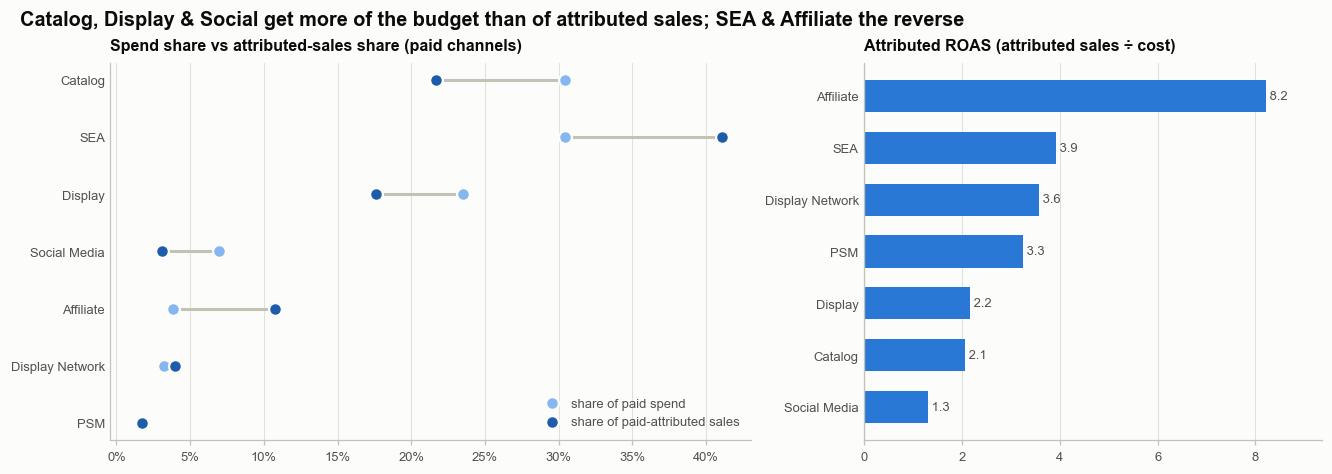

In [28]:
paid_spend_share = cost.sum() / cost.sum().sum()
paid_sales_share = sales[PAID].sum() / sales[PAID].sum().sum()
roas = sales[PAID].sum() / cost.sum()
order = paid_spend_share.sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained",
                         gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for i, ch in enumerate(order):
    ax.plot([paid_spend_share[ch], paid_sales_share[ch]], [i, i], color=AXIS, lw=2, zorder=1)
ax.scatter(paid_spend_share[order], range(len(order)), s=70, color=LIGHT_ACCENT, zorder=2,
           edgecolor=SURFACE, linewidth=1.5, label="share of paid spend")
ax.scatter(paid_sales_share[order], range(len(order)), s=70, color=DARK_ACCENT, zorder=3,
           edgecolor=SURFACE, linewidth=1.5, label="share of paid-attributed sales")
ax.set_yticks(range(len(order)), order)
ax.xaxis.set_major_formatter(PCT)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.legend(loc="lower right")
ax.set_title("Spend share vs attributed-sales share (paid channels)")

ranked_bars(axes[1], roas, color=ACCENT, fmt="{:.1f}")
axes[1].set_title("Attributed ROAS (attributed sales ÷ cost)")
headline(fig, "Catalog, Display & Social get more of the budget than of attributed sales; SEA & Affiliate the reverse")
save(fig, "spend_vs_sales_share")
plt.show()

- **Catalog** (30.5 % of spend) and **SEA** (30.4 %) are the two biggest budgets, followed by **Display** (23.5 %).
- On an *attributed* basis, Affiliate (ROAS ≈ 8) and SEA (≈ 4) look most efficient; Catalog (≈ 2.1), Display (≈ 2.2) and Social (≈ 1.3) look
  weakest. **These ROAS figures are not incremental**: last-touch attribution over-credits lower-funnel channels (SEA, Affiliate harvest
  demand that others created) and under-credits the catalog, whose halo lifts other channels (Section 10). This is exactly the gap an MMM
  is meant to close.

### 7.2 Spend over time

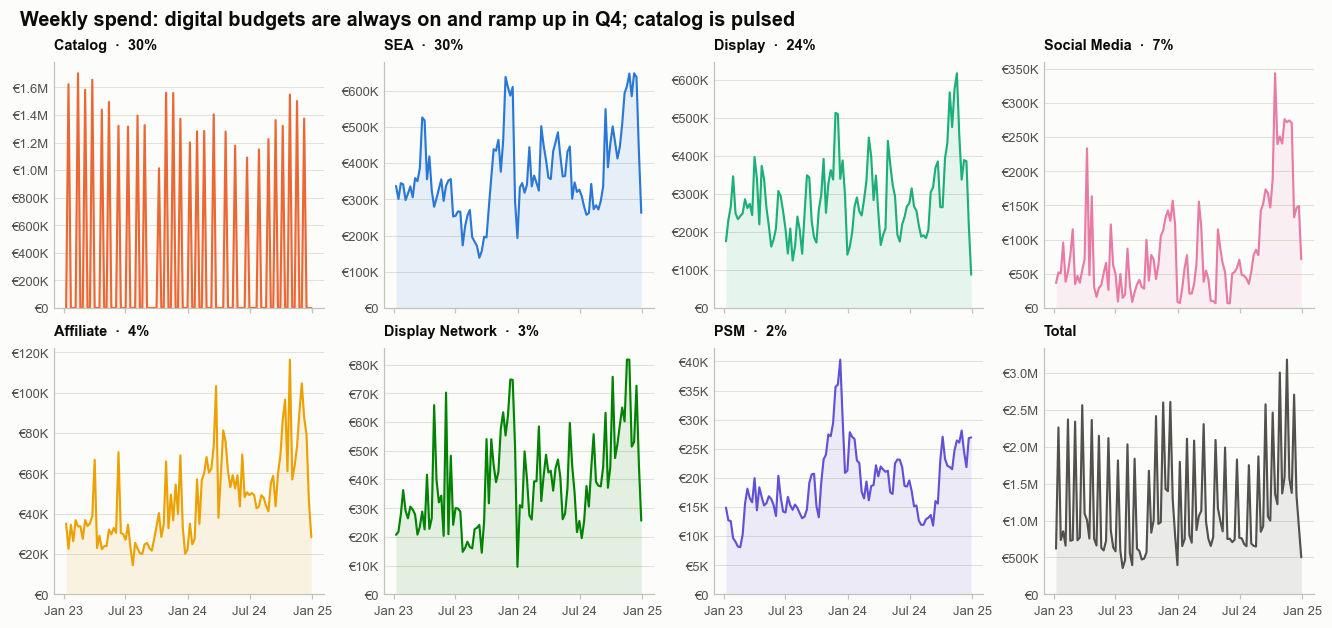

In [29]:
weeks_complete = y.resample("W-SUN").count() == 7
weekly_cost = cost.resample("W-SUN").sum()[weeks_complete]
weekly_cost["Total"] = weekly_cost[PAID].sum(axis=1)

fig, axes = plt.subplots(2, 4, figsize=(12, 5.6), sharex=True, layout="constrained")
for ax, ch in zip(axes.flat, list(spend_summary.index) + ["Total"]):
    color = INK_2 if ch == "Total" else COLOR[ch]
    ax.plot(weekly_cost.index, weekly_cost[ch], color=color, lw=1.4)
    ax.fill_between(weekly_cost.index, weekly_cost[ch], color=color, alpha=0.1, lw=0)
    ax.set_title(f"{ch}" if ch == "Total" else f"{ch}  ·  {spend_summary.loc[ch, 'share of spend']:.0%}",
                 fontsize=9.5)
    ax.yaxis.set_major_formatter(EUR)
    ax.set_ylim(bottom=0)
    date_axis(ax, months=(1, 7))
headline(fig, "Weekly spend: digital budgets are always on and ramp up in Q4; catalog is pulsed")
save(fig, "spend_small_multiples")
plt.show()

- **Digital channels are always on** (spend on 100 % of days) with seasonal ramps — little "on/off" variation, which makes their
  individual effects hard to identify (Section 11).
- **Catalog is a pulsed (flighted) medium**: ~€1.0–1.7 M every 3–5 weeks.
- **Social Media** has isolated Monday spikes (e.g. €160 K on 7 Oct 2024) and a large Q4 2024 ramp; **Affiliate** spend jumps in Q4 2024 —
  consistent with commission costs following sales.

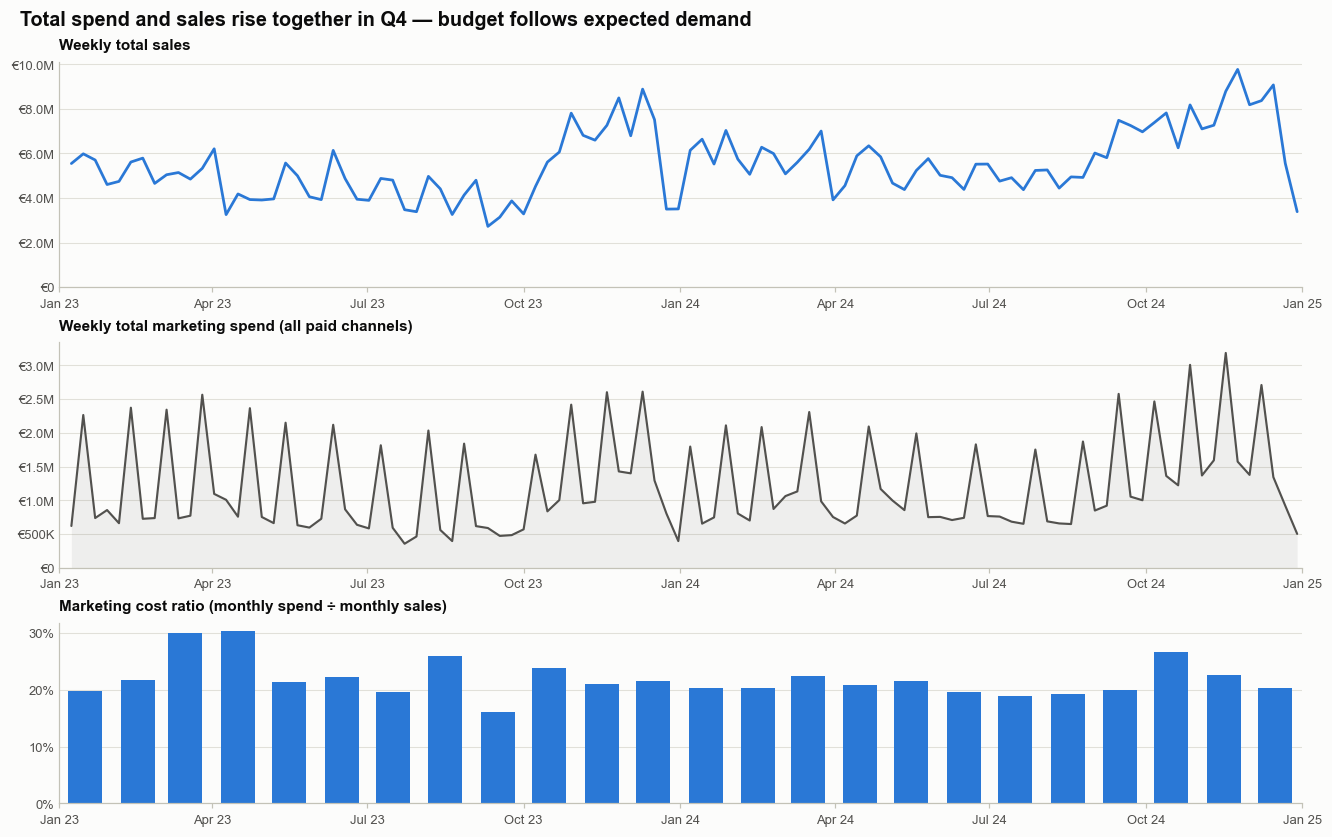

Correlation weekly total spend vs weekly total sales: 0.58


In [30]:
weekly_sales = y.resample("W-SUN").sum()[weeks_complete]
monthly_ratio = cost.loc[:"2024-12-31"].sum(axis=1).resample("MS").sum() / y_full.resample("MS").sum()

fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=False, layout="constrained",
                         gridspec_kw={"height_ratios": [1, 1, 0.8]})
axes[0].plot(weekly_sales.index, weekly_sales, color=ACCENT, lw=1.8)
axes[0].set_title("Weekly total sales", fontsize=10)
axes[1].plot(weekly_cost.index, weekly_cost["Total"], color=INK_2, lw=1.4)
axes[1].fill_between(weekly_cost.index, weekly_cost["Total"], color=INK_2, alpha=0.08, lw=0)
axes[1].set_title("Weekly total marketing spend (all paid channels)", fontsize=10)
axes[2].bar(monthly_ratio.index + pd.Timedelta(days=15), monthly_ratio.values, width=20, color=ACCENT)
axes[2].yaxis.set_major_formatter(PCT)
axes[2].set_title("Marketing cost ratio (monthly spend ÷ monthly sales)", fontsize=10)
for ax in axes:
    if ax is not axes[2]:
        ax.yaxis.set_major_formatter(EUR)
        ax.set_ylim(bottom=0)
    ax.set_xlim(pd.Timestamp("2023-01-01"), pd.Timestamp("2025-01-01"))
    date_axis(ax)
headline(fig, "Total spend and sales rise together in Q4 — budget follows expected demand")
save(fig, "spend_vs_sales_time")
plt.show()

weekly_corr = weekly_sales.corr(weekly_cost["Total"])
print(f"Correlation weekly total spend vs weekly total sales: {weekly_corr:.2f}")

Total spend tracks the season: budgets are raised when high demand is *expected* (Q4). This is the core **endogeneity** problem of
using budgets as predictors — part of the spend–sales correlation is "demand drives budget", not "budget drives demand". The cost ratio
fell in 2024 (spend +12 % vs sales +21 %).

### 7.3 Catalog send-outs

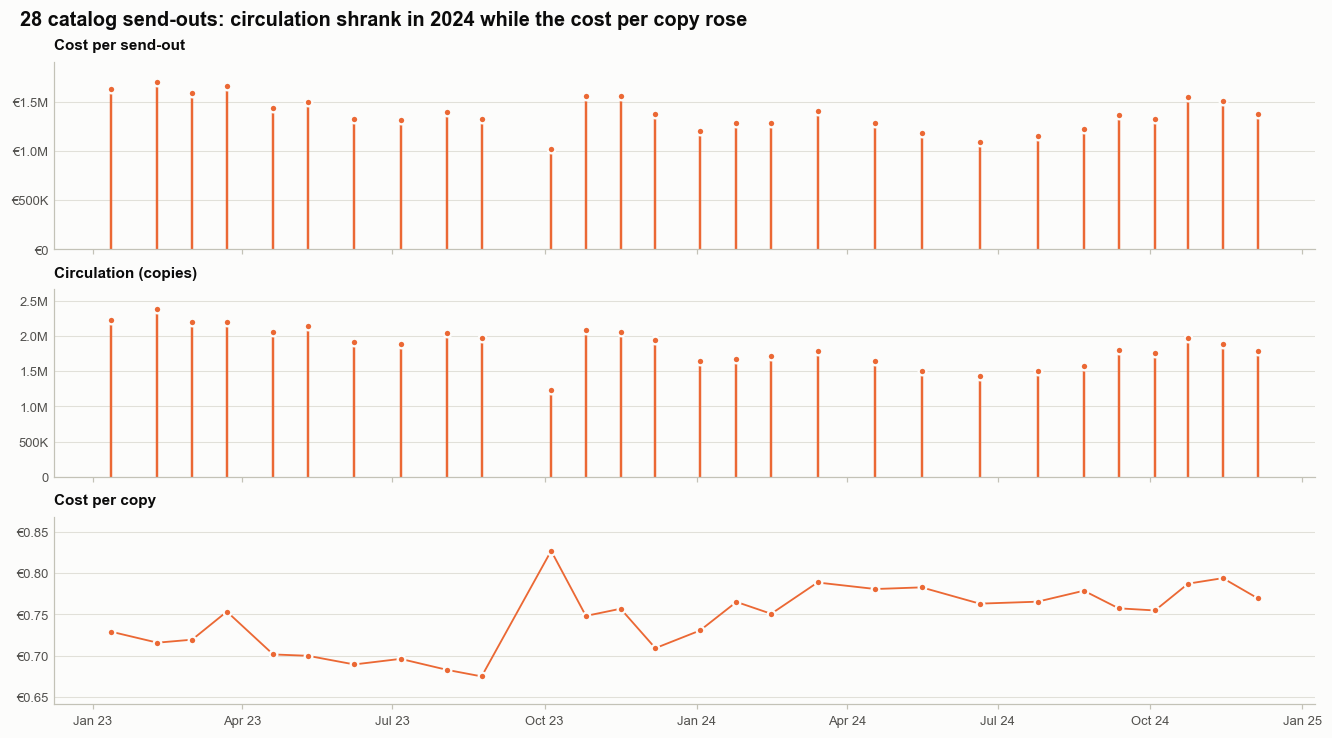

,cost,circulation,cost per copy
date,,,
2023,"€1,454,251","2,021,735",€0.722
2024,"€1,299,842","1,688,962",€0.769


Send-out weekdays: {'Thu': 26, 'Wed': 1, 'Fri': 1}
Gaps between send-outs (days): {20.0: 1, 21.0: 11, 22.0: 2, 27.0: 1, 28.0: 8, 35.0: 3, 42.0: 1}


In [31]:
catalog = pd.DataFrame({
    "cost": cost_wide.loc[send_dates, "Catalog"],
    "circulation": impr_wide.loc[send_dates, "Catalog"],
})
catalog["cost per copy"] = catalog["cost"] / catalog["circulation"]
catalog["weekday"] = catalog.index.strftime("%a")
catalog["gap (days)"] = catalog.index.to_series().diff().dt.days

fig, axes = plt.subplots(3, 1, figsize=(12, 6.6), sharex=True, layout="constrained")
specs = [("cost", "Cost per send-out", EUR), ("circulation", "Circulation (copies)", NUM),
         ("cost per copy", "Cost per copy", mticker.FormatStrFormatter("€%.2f"))]
for ax, (col, title, fmt) in zip(axes, specs):
    if col == "cost per copy":   # a ratio on a cropped axis: connected dots, not stems from zero
        ax.plot(catalog.index, catalog[col], color=COLOR["Catalog"], lw=1.2, marker="o", ms=5,
                mec=SURFACE, mew=1.5)
        ax.set_ylim(catalog[col].min() * 0.95, catalog[col].max() * 1.05)
    else:
        ax.vlines(catalog.index, 0, catalog[col], color=COLOR["Catalog"], lw=1.6)
        ax.plot(catalog.index, catalog[col], "o", color=COLOR["Catalog"], ms=5, mec=SURFACE, mew=1.5)
        ax.set_ylim(0, catalog[col].max() * 1.12)
    ax.set_title(title, fontsize=10)
    ax.yaxis.set_major_formatter(fmt)
date_axis(axes[-1])
headline(fig, "28 catalog send-outs: circulation shrank in 2024 while the cost per copy rose")
save(fig, "catalog_sendouts")
plt.show()

display(catalog.groupby(catalog.index.year)[["cost", "circulation", "cost per copy"]].mean()
        .style.format({"cost": "€{:,.0f}", "circulation": "{:,.0f}", "cost per copy": "€{:.3f}"})
        .set_caption("Average per send-out"))
print("Send-out weekdays:", catalog["weekday"].value_counts().to_dict())
print("Gaps between send-outs (days):", catalog["gap (days)"].value_counts().sort_index().to_dict())

- Send-outs are **almost always Thursdays** (26 of 28) at a 3–5-week rhythm; the only 42-day gap is Aug 24 → Oct 5 2023.
- **Cost ≈ circulation × €0.67–0.83** (r ≈ 0.94): average circulation fell ~16 % in 2024 (2.02 M → 1.69 M copies) while the cost per
  copy rose ~6.5 % (€0.72 → €0.77) — print/postage inflation. Circulation, not cost, is the better *exposure* measure.
- With only 28 events and a near-constant size, the data says a lot about *whether/when* the catalog works, but little about
  *how much more* a bigger catalog would deliver (saturation).

### 7.4 Spend by weekday

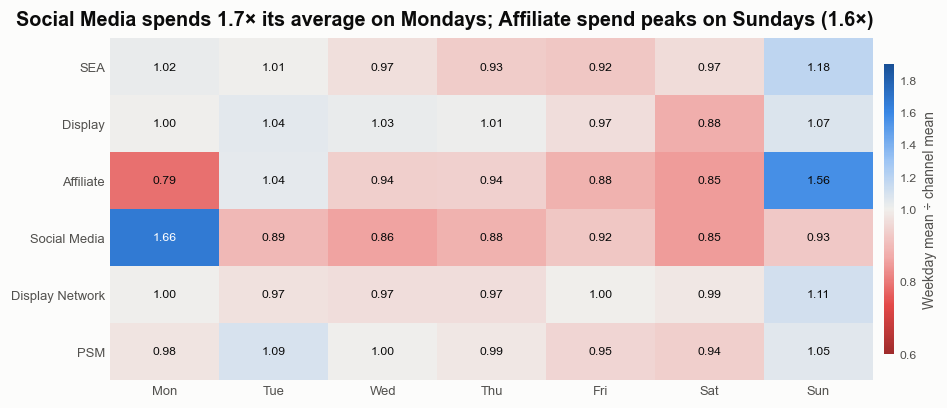

In [32]:
spend_wk = cost[PAID_DIGITAL].groupby(cost.index.dayofweek).mean() / cost[PAID_DIGITAL].mean()
spend_wk.index = DOW
fig, ax = plt.subplots(figsize=(8.5, 3.6), layout="constrained")
heatmap(ax, spend_wk.T, cmap=DIV, norm=TwoSlopeNorm(vcenter=1.0, vmin=0.6, vmax=1.9),
        cbar_label="Weekday mean ÷ channel mean")
headline(fig, "Social Media spends 1.7× its average on Mondays; Affiliate spend peaks on Sundays (1.6×)")
save(fig, "spend_weekday_index")
plt.show()

Weekly spend patterns differ by channel: Social Media is **front-loaded on Mondays** (campaign launches), Affiliate costs peak on
**Sundays** — the same day sales peak, again consistent with commission-based costs *following* demand. SEA also leans to Sunday
(CPC-billed: more searches → more clicks → more cost).

## 8. Media funnel & efficiency

### 8.1 How do cost, exposure and attributed sales relate within each channel?

This tells us **how each channel is billed** and which metric is the right *exposure* variable for an MMM.

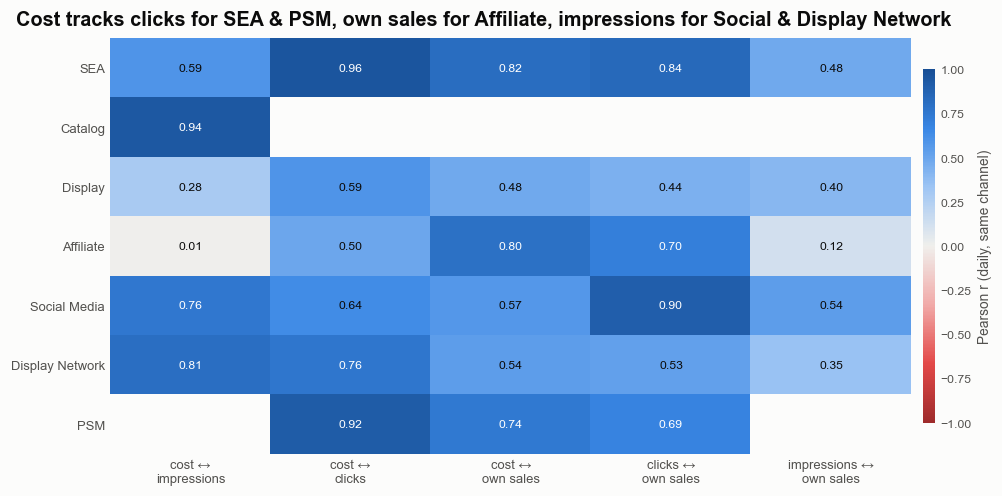

In [33]:
funnel = {}
for ch in PAID:
    d = raw[(raw["channel"] == ch) & raw["costs"].notna()]
    funnel[ch] = {
        "cost ↔\nimpressions": d["costs"].corr(d["impressions"]),
        "cost ↔\nclicks": d["costs"].corr(d["clicks"]) if d["clicks"].std() > 0 else np.nan,
        "cost ↔\nown sales": d["costs"].corr(d["sales_by_channel"]) if ch != "Catalog" else np.nan,
        "clicks ↔\nown sales": d["clicks"].corr(d["sales_by_channel"]) if d["clicks"].std() > 0 else np.nan,
        "impressions ↔\nown sales": d["impressions"].corr(d["sales_by_channel"]) if ch != "Catalog" else np.nan,
    }
funnel = pd.DataFrame(funnel).T

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
heatmap(ax, funnel, cmap=DIV, norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1),
        cbar_label="Pearson r (daily, same channel)")
headline(fig, "Cost tracks clicks for SEA & PSM, own sales for Affiliate, impressions for Social & Display Network")
save(fig, "funnel_correlations")
plt.show()

| Channel | Strongest cost link | Likely billing | Exposure metric for MMM |
|---|---|---|---|
| SEA | clicks (r ≈ 0.96) | CPC | clicks (or spend) |
| PSM | clicks (r ≈ 0.92) | CPC | clicks (no impressions exist) |
| Affiliate | **own sales (r ≈ 0.80)** | commission (~12 % of sales) | spend is an *outcome* → treat with care |
| Social Media | impressions (r ≈ 0.76) | CPM | impressions |
| Display Network | impressions (r ≈ 0.81) | CPM | impressions |
| Display | weak links (impr. r ≈ 0.28) | mixed / programmatic | impressions, sensitivity-check spend |
| Catalog | circulation (r ≈ 0.94, n = 28) | print + postage | circulation |

Catalog cells for own-sales are blank on purpose — on its send-out day the catalog has barely started to sell. Note Social Media's
clicks ↔ own sales r = 0.90: both jump together at the August 2024 regime change (8.3).

### 8.2 Efficiency KPIs over time

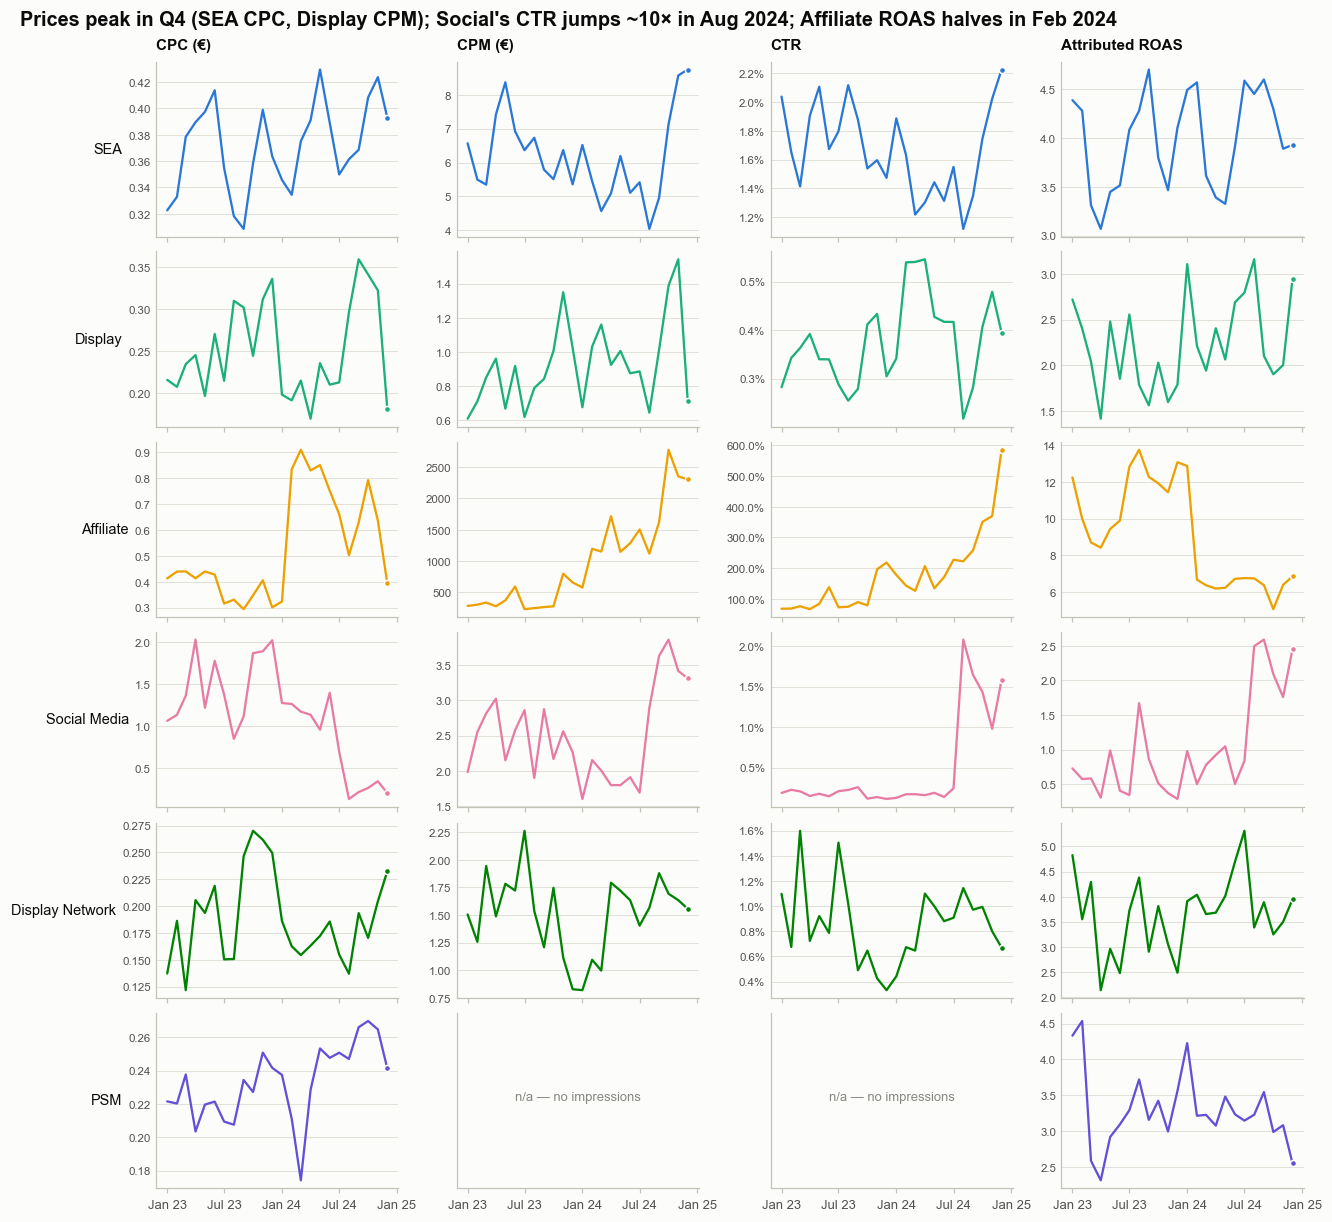

In [34]:
m_cost = cost_wide.loc[:"2024-12-31", PAID_DIGITAL].resample("MS").sum(min_count=1)
m_click = click_wide.loc[:"2024-12-31", PAID_DIGITAL].resample("MS").sum(min_count=1)
m_impr = impr_wide.loc[:"2024-12-31", PAID_DIGITAL].resample("MS").sum(min_count=1)
m_sales = sales.loc[:"2024-12-31", PAID_DIGITAL].resample("MS").sum()
kpi = {
    "CPC (€)": m_cost / m_click,
    "CPM (€)": m_cost / m_impr * 1000,
    "CTR": m_click / m_impr,
    "Attributed ROAS": m_sales / m_cost,
}

fig, axes = plt.subplots(len(PAID_DIGITAL), len(kpi), figsize=(12, 11), sharex=True,
                         layout="constrained")
for j, (name, frame) in enumerate(kpi.items()):
    for i, ch in enumerate(PAID_DIGITAL):
        ax = axes[i, j]
        s = frame[ch]
        ax.plot(s.index, s.values, color=COLOR[ch], lw=1.5)
        if s.notna().any():
            ax.plot(s.index[-1], s.values[-1], "o", color=COLOR[ch], ms=4, mec=SURFACE, mew=1)
        else:
            ax.text(0.5, 0.5, "n/a — no impressions", transform=ax.transAxes, ha="center",
                    color=MUTED, fontsize=8.5)
            ax.set_yticks([])
            ax.grid(False)
        if i == 0:
            ax.set_title(name, fontsize=10)
        if j == 0:
            ax.set_ylabel(ch, rotation=0, ha="right", va="center", fontsize=9.5, color=INK)
        if name == "CTR":
            ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=1))
        ax.tick_params(axis="y", labelsize=7.5)
        date_axis(ax, months=(1, 7))
headline(fig, "Prices peak in Q4 (SEA CPC, Display CPM); Social's CTR jumps ~10× in Aug 2024; Affiliate ROAS halves in Feb 2024")
save(fig, "efficiency_kpis")
plt.show()

quarterly = pd.concat({name: frame.resample("QS").mean() for name, frame in kpi.items()}, axis=1)
quarterly.index = quarterly.index.to_period("Q")
display(quarterly.T.dropna(how="all").style.format("{:.3f}", na_rep="–")
        .background_gradient(cmap=SEQ, axis=1)
        .set_caption("Quarterly mean of the monthly KPI (each row coloured on its own scale)"))

- **Seasonal media prices:** SEA CPC moves between ~€0.31 and ~€0.43 with highs in Q2 and Q4; Display CPM rises from ~€0.6 to €1.2–1.5
  in each Q4. The *same euro buys less exposure* in peak season — a spend-only model silently assumes constant prices; exposure-based
  MMM inputs (clicks / impressions) or price indices help.
- **Affiliate:** recorded impressions are tiny (CTR > 100 %), so CPM and CTR are meaningless. Its CPC and cost-to-sales ratio *step up in
  Feb 2024* and attributed ROAS halves (~12 → ~6.5) — a commission-model change, i.e. a **second structural break**.
- **Social Media** changes character in August 2024: CTR ~0.2 % → ~1.5–2 %, CPC ~€1.2 → ~€0.3, attributed ROAS ~0.8 → ~2.1 — see below.

### 8.3 Social Media regime change (Aug 2024)

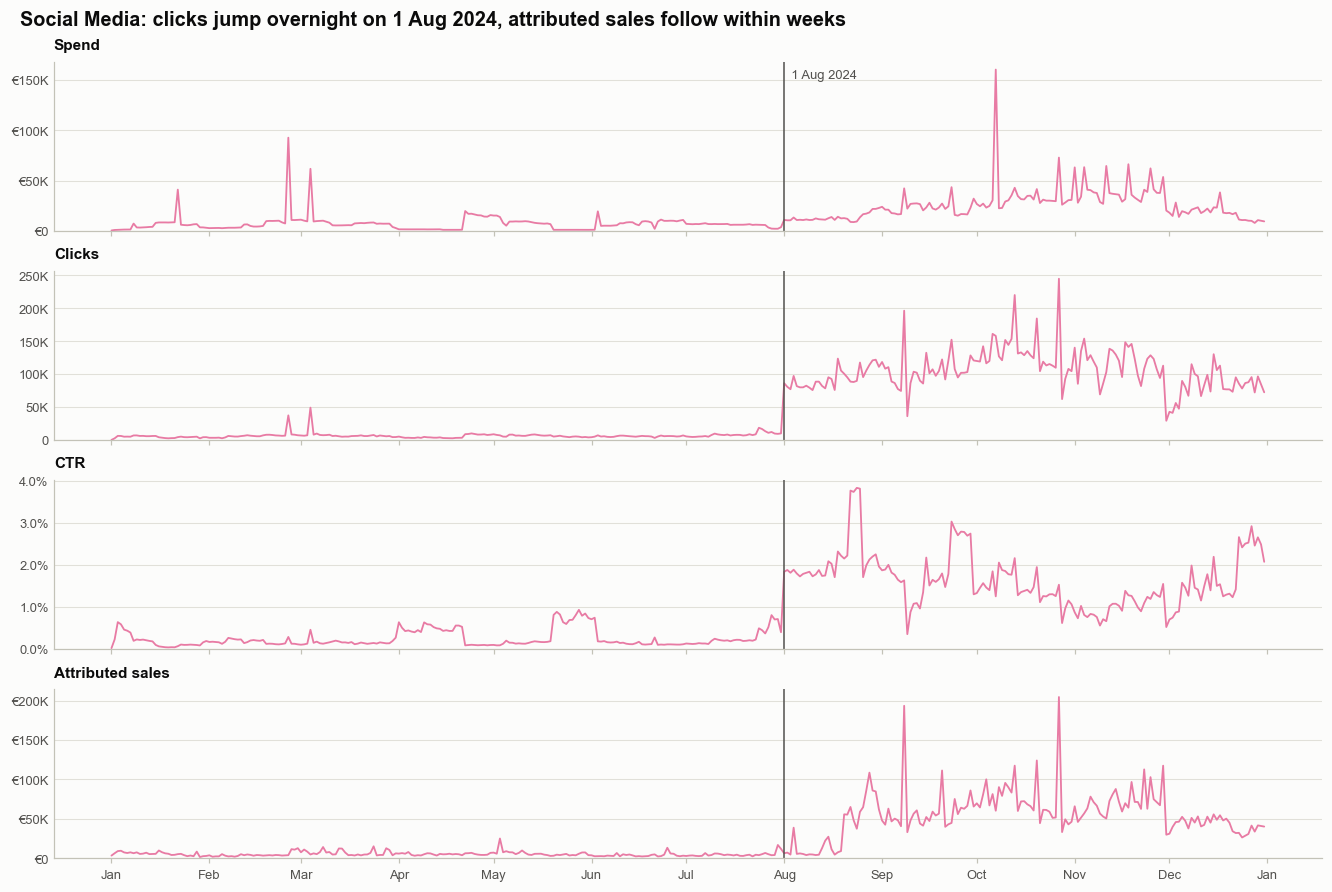

,Jan–Jul 2024 (daily mean),Aug–Dec 2024 (daily mean),ratio
Spend,"€7,029","€25,754",×3.7
Clicks,"6,396","105,692",×16.5
CTR,0.25%,1.63%,×6.5
Attributed sales,"€5,401","€55,853",×10.3


In [35]:
soc = pd.DataFrame({
    "Spend": cost_wide["Social Media"], "Clicks": click_wide["Social Media"],
    "CTR": click_wide["Social Media"] / impr_wide["Social Media"],
    "Attributed sales": sales_wide["Social Media"],
}).loc["2024-01-01":"2024-12-31"]
break_date = pd.Timestamp("2024-08-01")

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True, layout="constrained")
fmts = {"Spend": EUR, "Clicks": NUM, "CTR": mticker.PercentFormatter(1.0, decimals=1),
        "Attributed sales": EUR}
for ax, col in zip(axes, soc.columns):
    ax.plot(soc.index, soc[col], color=COLOR["Social Media"], lw=1.2)
    ax.axvline(break_date, color=INK_2, lw=1)
    ax.set_title(col, fontsize=10)
    ax.yaxis.set_major_formatter(fmts[col])
    ax.set_ylim(bottom=0)
axes[0].text(break_date, axes[0].get_ylim()[1] * 0.9, "  1 Aug 2024", color=INK_2, fontsize=8.5)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
headline(fig, "Social Media: clicks jump overnight on 1 Aug 2024, attributed sales follow within weeks")
save(fig, "social_regime_change")
plt.show()

before = soc.loc[:"2024-07-31"].mean()
after = soc.loc["2024-08-01":].mean()
regime = pd.DataFrame({"Jan–Jul 2024 (daily mean)": before, "Aug–Dec 2024 (daily mean)": after,
                       "ratio": after / before})
row_fmt = {"Spend": "€{:,.0f}", "Clicks": "{:,.0f}", "CTR": "{:.2%}", "Attributed sales": "€{:,.0f}"}
styler = regime.style.format("×{:.1f}", subset=["ratio"])
for row, f in row_fmt.items():
    styler = styler.format(f, subset=pd.IndexSlice[[row], regime.columns[:2]])
display(styler)

On **1 Aug 2024** Social Media clicks jump ~8× overnight (≈ 10 K → 86 K/day) while spend only triples (≈ €3.6 K → €10.9 K/day); average CTR moves
from ~0.25 % to ~1.6 %, and attributed sales step up to a new level about two to three weeks later. Averaged over Aug–Dec vs Jan–Jul:
spend ×3.7, clicks ×16.5, attributed sales ×10. This looks like a **change in campaign type or tracking/attribution set-up**, not a
gradual performance gain. Implications:

- A single Social Media coefficient across the whole period is mis-specified → add a **regime dummy / interaction** or treat the periods
  separately; confirm the cause with the marketing team.
- The Q4 2024 hold-out sits entirely in the new regime, with only ~2 months of new-regime history in training.

### 8.4 Affiliate — cost follows sales

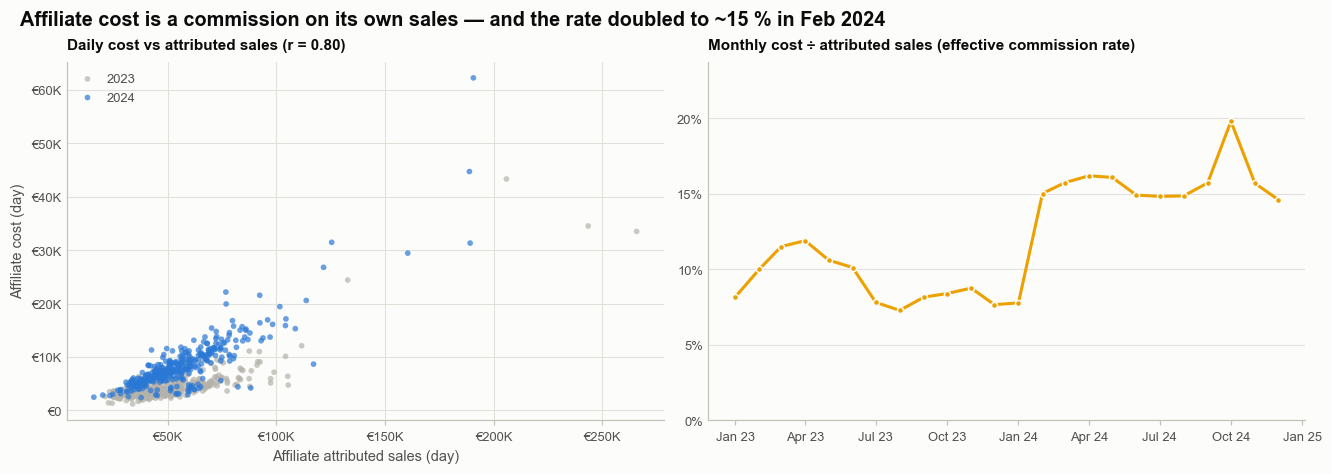

In [36]:
aff = pd.DataFrame({"cost": cost["Affiliate"], "sales": sales["Affiliate"]})
aff_monthly = aff.loc[:"2024-12-31"].resample("MS").sum()
aff_monthly["commission rate"] = aff_monthly["cost"] / aff_monthly["sales"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
ax = axes[0]
for yr, color in [(2023, NEUTRAL), (2024, ACCENT)]:
    d = aff[aff.index.year == yr]
    ax.scatter(d["sales"], d["cost"], s=14, color=color, alpha=0.7, edgecolor="none", label=str(yr))
ax.xaxis.set_major_formatter(EUR)
ax.yaxis.set_major_formatter(EUR)
ax.set_xlabel("Affiliate attributed sales (day)")
ax.set_ylabel("Affiliate cost (day)")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper left")
ax.set_title(f"Daily cost vs attributed sales (r = {aff['cost'].corr(aff['sales']):.2f})", fontsize=10)
ax = axes[1]
ax.plot(aff_monthly.index, aff_monthly["commission rate"], color=COLOR["Affiliate"], lw=2,
        marker="o", ms=4, mec=SURFACE)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, aff_monthly["commission rate"].max() * 1.2)
ax.set_title("Monthly cost ÷ attributed sales (effective commission rate)", fontsize=10)
date_axis(ax)
headline(fig, "Affiliate cost is a commission on its own sales — and the rate doubled to ~15 % in Feb 2024")
save(fig, "affiliate_commission")
plt.show()

Affiliate cost is a **commission share of affiliate sales** (daily r = 0.80): ~7–12 % through 2023, then a step to ~15–16 % in
February 2024 (up to ~20 % in Oct 2024). The two years form two clouds with different slopes. Its high correlation with total sales
(r = 0.76, the highest of all channels) is therefore largely **reverse causality**: when demand is high, affiliates earn more commission.
In a forecast, *planned* affiliate budget is effectively a forecast of sales itself — a leakage risk.

### 8.5 Spend vs total sales — response shape

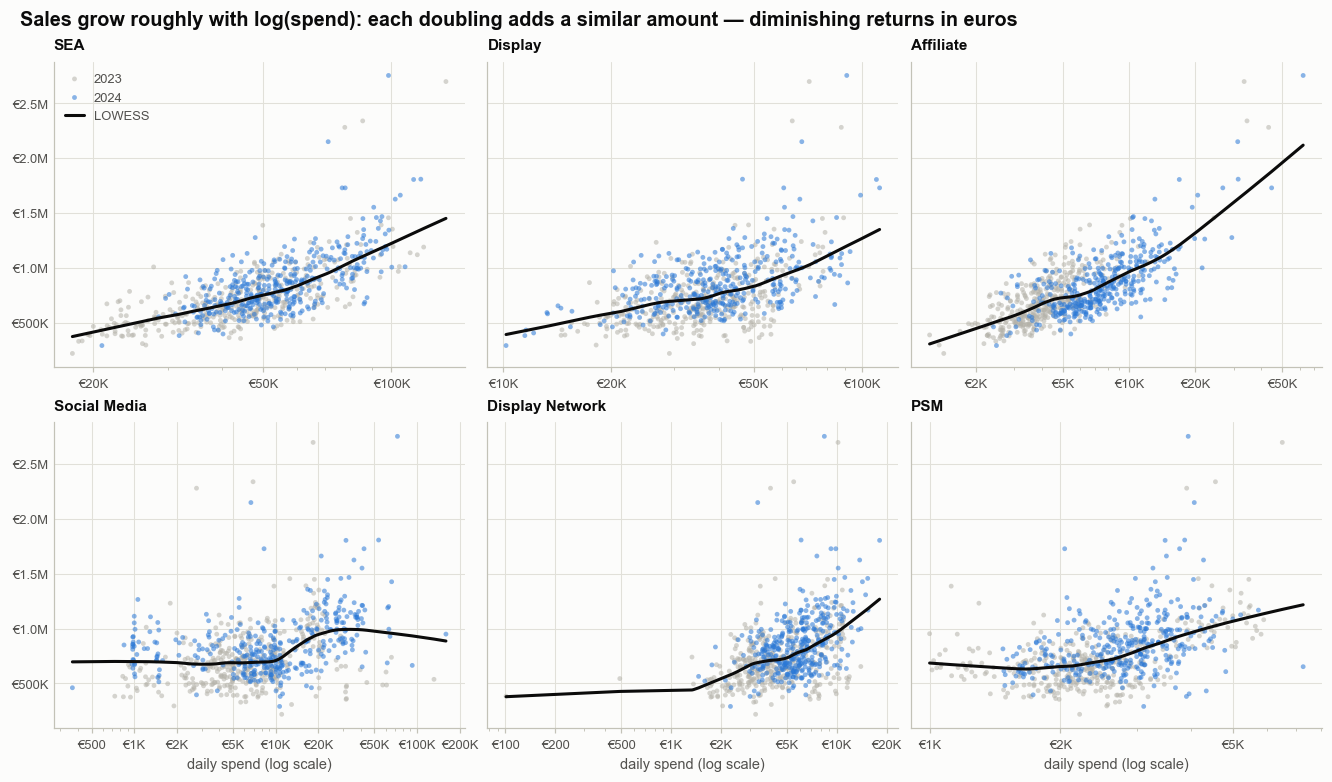

,raw log-log slope,after trend + calendar
SEA,0.67,0.70
Display,0.46,0.32
Affiliate,0.45,0.49
Social Media,0.12,0.05
Display Network,0.30,0.16
PSM,0.44,0.25


In [37]:
def calendar_design(index):
    frame = pd.DataFrame({"month": index.month.astype(str), "dow": index.dayofweek.astype(str)},
                         index=index)
    X = pd.get_dummies(frame, drop_first=True).astype(float)
    X.insert(0, "trend", np.arange(len(index)) / len(index))
    X.insert(0, "const", 1.0)
    return X


def residualize(s, X):
    beta, *_ = np.linalg.lstsq(X.to_numpy(), s.to_numpy(), rcond=None)
    return s - X.to_numpy() @ beta


X_cal = calendar_design(y.index)
elasticity = {}
fig, axes = plt.subplots(2, 3, figsize=(12, 7), layout="constrained", sharey=True)
for ax, ch in zip(axes.flat, PAID_DIGITAL):
    x = cost[ch]
    for yr, color in [(2023, NEUTRAL), (2024, ACCENT)]:
        m = y.index.year == yr
        ax.scatter(x[m], y[m], s=10, color=color, alpha=0.55, edgecolor="none", label=str(yr))
    fit = lowess(y.values, np.log(x.values), frac=0.4, return_sorted=True)
    ax.plot(np.exp(fit[:, 0]), fit[:, 1], color=INK, lw=2, label="LOWESS")
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.xaxis.set_major_formatter(EUR)
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.yaxis.set_major_formatter(EUR)
    ax.grid(axis="x", visible=True)
    ax.set_title(ch, fontsize=10)
    raw_slope = np.polyfit(np.log(x), np.log(y), 1)[0]
    adj_slope = np.polyfit(residualize(np.log(x), X_cal), residualize(np.log(y), X_cal), 1)[0]
    elasticity[ch] = {"raw log-log slope": raw_slope, "after trend + calendar": adj_slope}
axes[0, 0].legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("daily spend (log scale)")
headline(fig, "Sales grow roughly with log(spend): each doubling adds a similar amount — diminishing returns in euros")
save(fig, "spend_response")
plt.show()

display(pd.DataFrame(elasticity).T.style.format("{:.2f}")
        .set_caption("Univariate elasticity of total sales w.r.t. channel spend"))

- For SEA, Display and PSM the LOWESS curve is close to a straight line on a **log** spend axis: each *doubling* of spend goes with a
  similar absolute sales increase, i.e. **diminishing returns per euro** — the reason MMMs use a saturation curve (log / Hill).
- **Affiliate** bends *upwards*: on the very biggest sales days commissions explode because sales do (reverse causality, 8.4).
  **Social Media** is flat below ~€10 K/day and only rises in the post-August-2024 regime.
- Elasticities (log-log slopes) from these single-channel views shrink sharply for **Display, Display Network, PSM and Social** once trend
  and calendar are partialled out (e.g. Display 0.46 → 0.32, PSM 0.44 → 0.25) — their raw link is largely shared seasonality. **SEA
  (0.67 → 0.70) and Affiliate (0.45 → 0.49) do not shrink**: their costs track day-to-day demand mechanically (CPC, commission). These are
  *not* causal estimates (each channel alone, no adstock); they only bound the problem.

## 9. Correlation analysis

The brief asks for a correlation matrix of channels to sales. We look at it from several angles, because same-day Pearson correlation
alone is misleading for marketing data (lags, shared seasonality, non-linearity).

### 9.1 Correlation matrix — channel costs and total sales (daily)

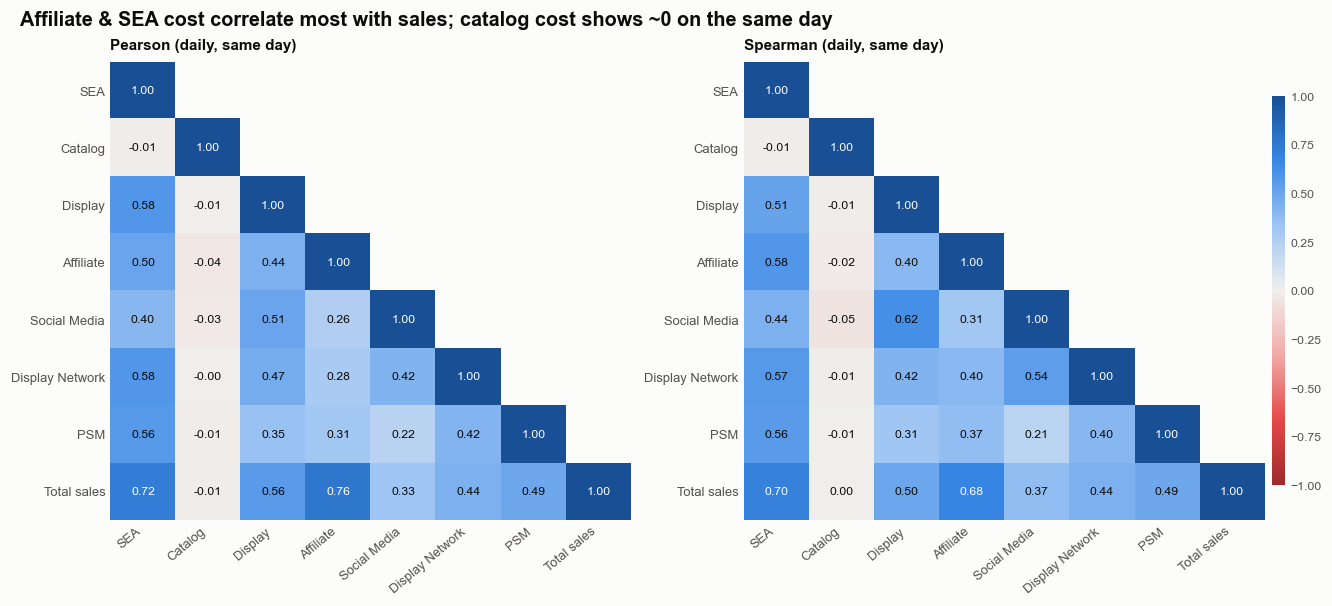

In [38]:
corr_input = cost[PAID].join(y.rename("Total sales"))
labels = list(corr_input.columns)


def lower_triangle(c):
    return c.where(np.tril(np.ones(c.shape, dtype=bool)))


fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), layout="constrained")
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = lower_triangle(corr_input.corr(method=method))
    heatmap(ax, c, cmap=DIV, norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1), xrot=40,
            cbar=method == "spearman")
    ax.set_title(f"{method.title()} (daily, same day)", fontsize=10)
headline(fig, "Affiliate & SEA cost correlate most with sales; catalog cost shows ~0 on the same day")
save(fig, "corr_matrix_costs")
plt.show()

- **Affiliate (0.76) and SEA (0.72)** have the strongest same-day correlation with total sales, then Display (0.56), PSM (0.49),
  Display Network (0.44), Social Media (0.33). Pearson and Spearman agree, so this is not driven by outliers alone.
- **Catalog: −0.01** — the biggest budget appears irrelevant on the same day, because its effect arrives days later (9.3).
- **Digital costs correlate with each other (0.22–0.58)**: they are planned together and follow the same season → multicollinearity.
- The two highest correlations belong to the channels whose **cost is mechanically tied to demand** (CPC and commission).

### 9.2 How robust are those correlations?

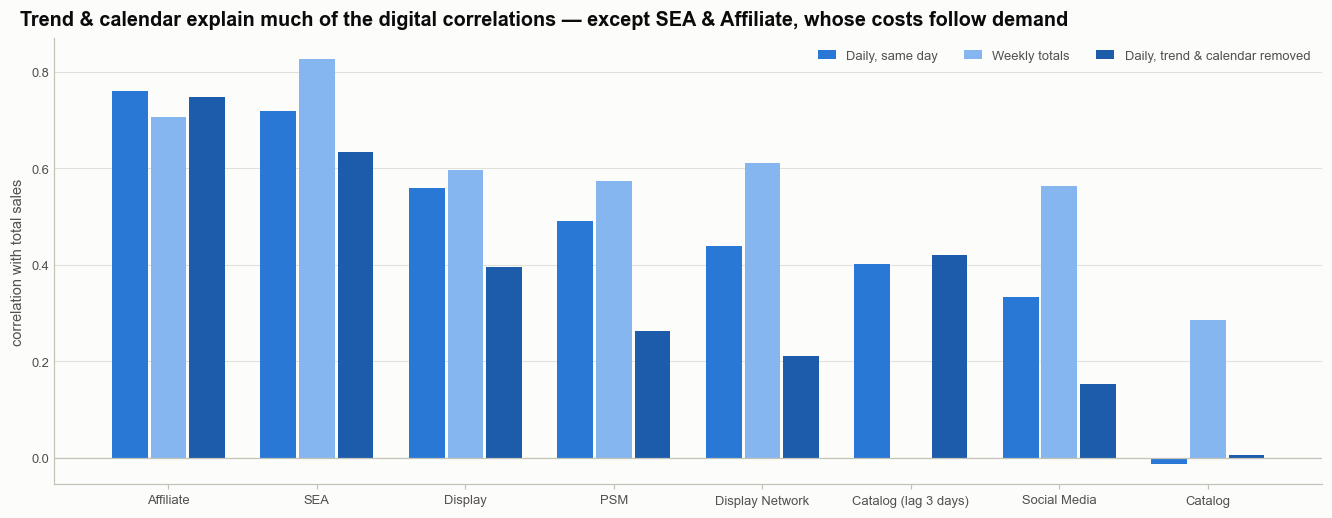

,"Daily, same day",Weekly totals,"Daily, trend & calendar removed"
Affiliate,0.76,0.71,0.75
SEA,0.72,0.83,0.63
Display,0.56,0.60,0.39
PSM,0.49,0.57,0.26
Display Network,0.44,0.61,0.21
Catalog (lag 3 days),0.40,–,0.42
Social Media,0.33,0.56,0.15
Catalog,-0.01,0.29,0.00


In [39]:
weekly_frame = corr_input.resample("W-SUN").sum()[weeks_complete]
resid_frame = corr_input.apply(lambda s: residualize(s, X_cal))
catalog_lag3 = cost["Catalog"].shift(3)

robust = pd.DataFrame({
    "Daily, same day": corr_input.corr()["Total sales"].drop("Total sales"),
    "Weekly totals": weekly_frame.corr()["Total sales"].drop("Total sales"),
    "Daily, trend & calendar removed": resid_frame.corr()["Total sales"].drop("Total sales"),
})
robust.loc["Catalog (lag 3 days)"] = [
    y.corr(catalog_lag3),
    np.nan,
    pd.Series(residualize(y, X_cal)).iloc[3:].corr(pd.Series(residualize(catalog_lag3.fillna(0), X_cal)).iloc[3:]),
]
robust = robust.loc[robust["Daily, same day"].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 4.6), layout="constrained")
x = np.arange(len(robust))
for k, (col, color) in enumerate(zip(robust.columns, [ACCENT, LIGHT_ACCENT, DARK_ACCENT])):
    ax.bar(x + (k - 1) * 0.26, robust[col], width=0.24, color=color, label=col)
ax.set_xticks(x, robust.index)
ax.axhline(0, color=AXIS, lw=0.8)
ax.set_ylabel("correlation with total sales")
ax.legend(loc="upper right", ncol=3)
headline(fig, "Trend & calendar explain much of the digital correlations — except SEA & Affiliate, whose costs follow demand")
save(fig, "corr_robustness")
plt.show()
display(robust.style.format("{:.2f}", na_rep="–"))

- **Weekly aggregation** averages out daily noise, so most correlations *rise* (SEA 0.83, Display Network 0.61, Social 0.56), and it
  absorbs the catalog's short lag (0.29 instead of −0.01). Weekly correlations look stronger but rest on only 104 points.
- **De-seasonalising** both sides (trend + month + weekday) cuts Display (0.56 → 0.39), PSM (0.49 → 0.26), Display Network (0.44 → 0.21)
  and Social (0.33 → 0.15): much of their raw correlation is "both go up in Q4". **Affiliate (0.75) and SEA (0.63) barely move** — their
  costs follow day-to-day demand (commission, CPC), so their correlation is not a clean media effect either.
- **Catalog with a 3-day lag** correlates 0.40 with sales, and 0.42 after de-seasonalising — the most robust media signal in the data.

### 9.3 Lagged cross-correlation (spend today → sales in *k* days)

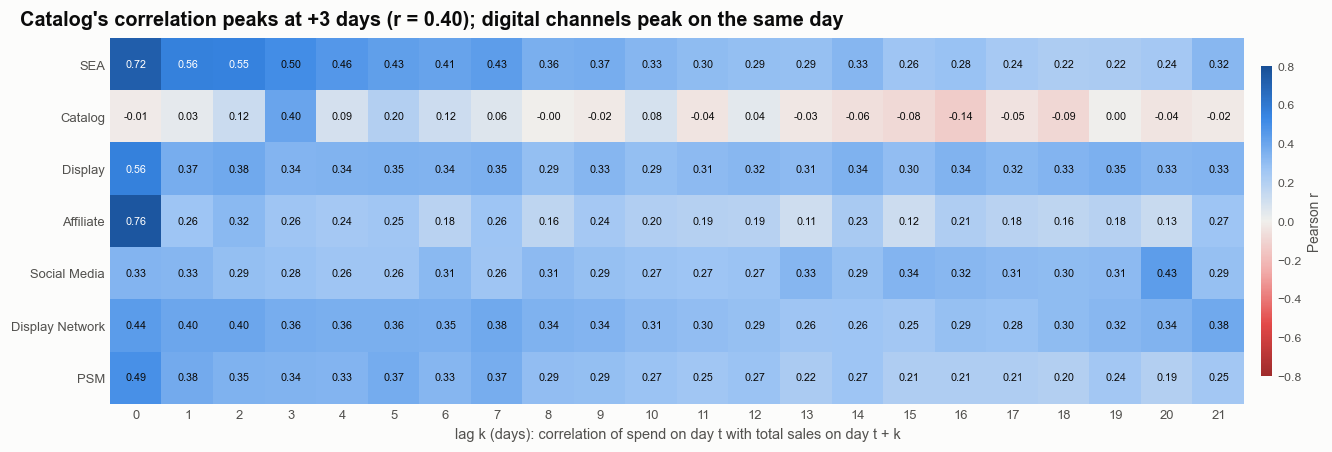

In [40]:
lags = range(0, 22)
lag_corr = pd.DataFrame({ch: [y.corr(cost[ch].shift(k)) for k in lags] for ch in PAID},
                        index=lags).T

fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
heatmap(ax, lag_corr, cmap=DIV, norm=TwoSlopeNorm(vcenter=0, vmin=-0.8, vmax=0.8),
        fmt="{:.2f}", fontsize=7, cbar_label="Pearson r")
ax.set_xlabel("lag k (days): correlation of spend on day t with total sales on day t + k")
headline(fig, "Catalog's correlation peaks at +3 days (r = 0.40); digital channels peak on the same day")
save(fig, "lag_correlation")
plt.show()

- **Catalog**: near zero at lag 0, **peaks at lag 3 (0.40)** with secondary bumps at lags 5–6 → a *delayed* response (a Thursday
  send-out hits the following Sunday). A standard geometric adstock (peak on day 0) is the wrong shape; use a **delayed / binomial
  adstock** or explicit distributed lags up to ~3 weeks.
- **Digital channels** peak at lag 0 and decay slowly — partly genuine carry-over, partly autocorrelation of spend itself (spend is
  smooth). Short geometric adstock is the natural assumption. (Social Media's isolated 0.43 at lag 20 is noise from a few Monday spikes.)

### 9.4 Channel interactions — attributed sales vs attributed sales

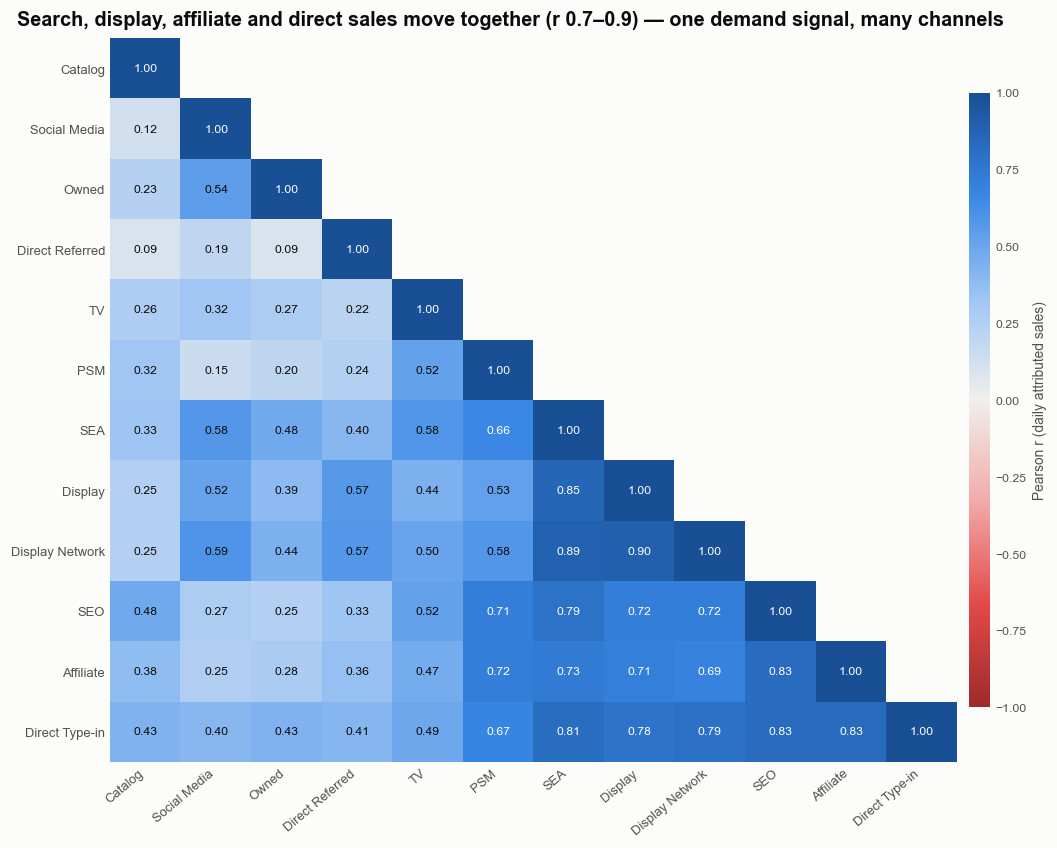

In [41]:
sales_corr = sales.corr()
order = sales_corr.index[leaves_list(linkage(1 - sales_corr.values[np.triu_indices(12, 1)], "average"))]
sales_corr = sales_corr.loc[order, order]

fig, ax = plt.subplots(figsize=(9.5, 7.6), layout="constrained")
heatmap(ax, lower_triangle(sales_corr), cmap=DIV, norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1),
        xrot=40, cbar_label="Pearson r (daily attributed sales)")
headline(fig, "Search, display, affiliate and direct sales move together (r 0.7–0.9) — one demand signal, many channels")
save(fig, "corr_channel_sales")
plt.show()

Channels are ordered by hierarchical clustering. A large block — **SEA, Display, Display Network, SEO, Affiliate, Direct Type-in** —
co-moves at r ≈ 0.7–0.9 day by day: largely *one* demand signal, split across channels by attribution (people triggered anywhere end
up searching, clicking a display retargeting ad or typing the URL). Catalog-attributed sales correlate moderately with SEO (0.48),
Direct Type-in (0.43) and Affiliate (0.38) — consistent with the **halo**. Social Media, Owned, Direct Referred and TV are more
idiosyncratic. Attributed sales per channel are therefore *not* independent effects and must not be used as features.

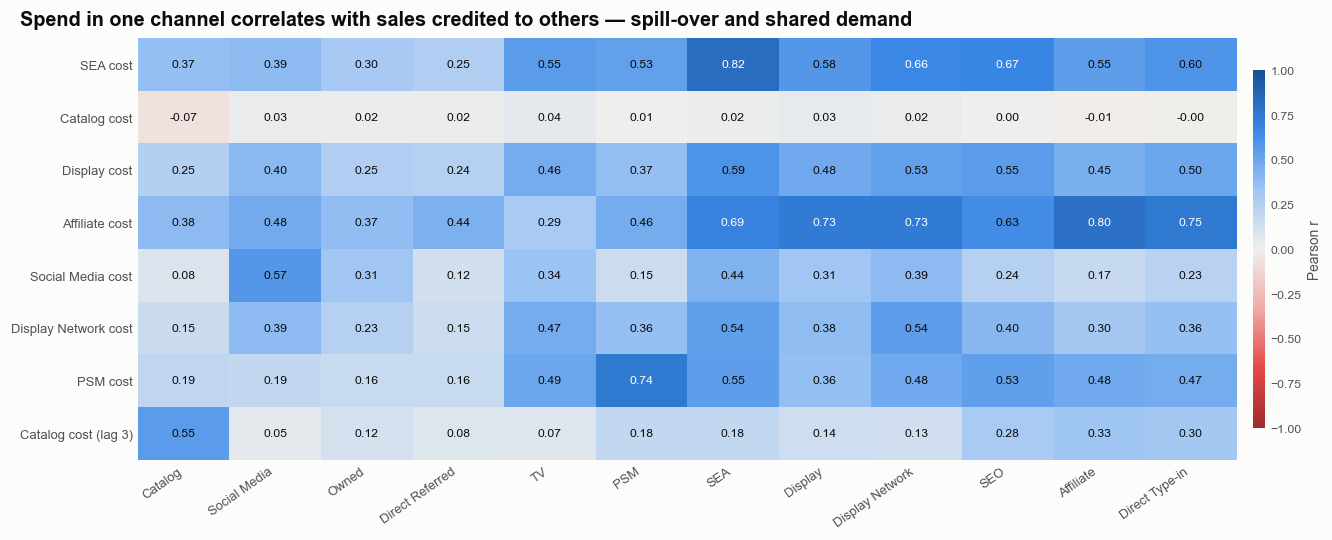

In [42]:
cross =pd.DataFrame({target: [cost[src].corr(sales[target]) for src in PAID] for target in order},
                     index=[f"{c} cost" for c in PAID])
cross.loc["Catalog cost (lag 3)"] = [catalog_lag3.corr(sales[t]) for t in order]

fig, ax = plt.subplots(figsize=(12, 4.8), layout="constrained")
heatmap(ax, cross, cmap=DIV, norm=TwoSlopeNorm(vcenter=0, vmin=-1, vmax=1), xrot=35,
        cbar_label="Pearson r")
headline(fig, "Spend in one channel correlates with sales credited to others — spill-over and shared demand")
save(fig, "corr_cost_vs_channel_sales")
plt.show()

Reading across a row shows where a channel's spend "shows up". SEA cost correlates with *SEO* (0.67), *Display Network* (0.66) and
*Direct Type-in* (0.60) sales almost as much as with SEA sales (0.82) — shared demand (CPC spend rises when people search anyway) and
spill-over. **Affiliate cost** correlates 0.63–0.80 with six channels' sales: it behaves like a thermometer of total demand. Same-day
catalog cost is unrelated to every channel, but the **3-day-lagged catalog cost** correlates with catalog (0.55), Affiliate (0.33),
Direct Type-in (0.30) and SEO (0.28) sales — the halo in numbers. Only total-sales modelling captures these cross-effects.

### 9.5 Multicollinearity

In [43]:
def vif_table(frame):
    X = (frame - frame.mean()) / frame.std()
    X.insert(0, "const", 1.0)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=frame.columns)


vif = pd.DataFrame({
    "VIF daily log1p(spend)": vif_table(np.log1p(cost[PAID])),
    "VIF weekly log1p(spend)": vif_table(np.log1p(weekly_cost[PAID])),
    "VIF daily + trend & calendar": [
        variance_inflation_factor(
            pd.concat([np.log1p(cost[PAID]), X_cal.drop(columns="const")], axis=1)
            .pipe(lambda d: (d - d.mean()) / d.std()).fillna(0).assign(const=1.0).values, i)
        for i in range(len(PAID))
    ],
})
display(vif.style.format("{:.1f}").background_gradient(cmap=SEQ, vmin=1, vmax=10))

,VIF daily log1p(spend),VIF weekly log1p(spend),VIF daily + trend & calendar
channel,,,
SEA,2.3,2.7,3.3
Catalog,1.0,1.0,1.3
Display,1.9,2.3,2.3
Affiliate,1.6,1.8,2.7
Social Media,1.8,2.2,2.6
Display Network,1.7,2.1,1.9
PSM,1.4,1.4,2.2


VIFs stay **below ~3.5 in every variant** (daily, weekly, with trend & calendar), so classical multicollinearity between spends is only
moderate — SEA is the most entangled (3.3 with calendar terms). The harder identification problem is elsewhere: a third to a half of
each digital channel's spend is explained by trend + calendar (Section 11), every digital channel is always on, and two cost series
(SEA, Affiliate) are driven by demand. Ridge regularisation or Bayesian priors are needed, and individual digital coefficients should
be interpreted with caution.

## 10. Catalog deep-dive: delayed effect & halo

The catalog is the biggest budget and the source of the largest demand spikes, so it deserves its own event study.
With 28 send-outs, each "day *k* after a send-out" has up to 28 observations.

### 10.1 Event study — total sales by days since send-out

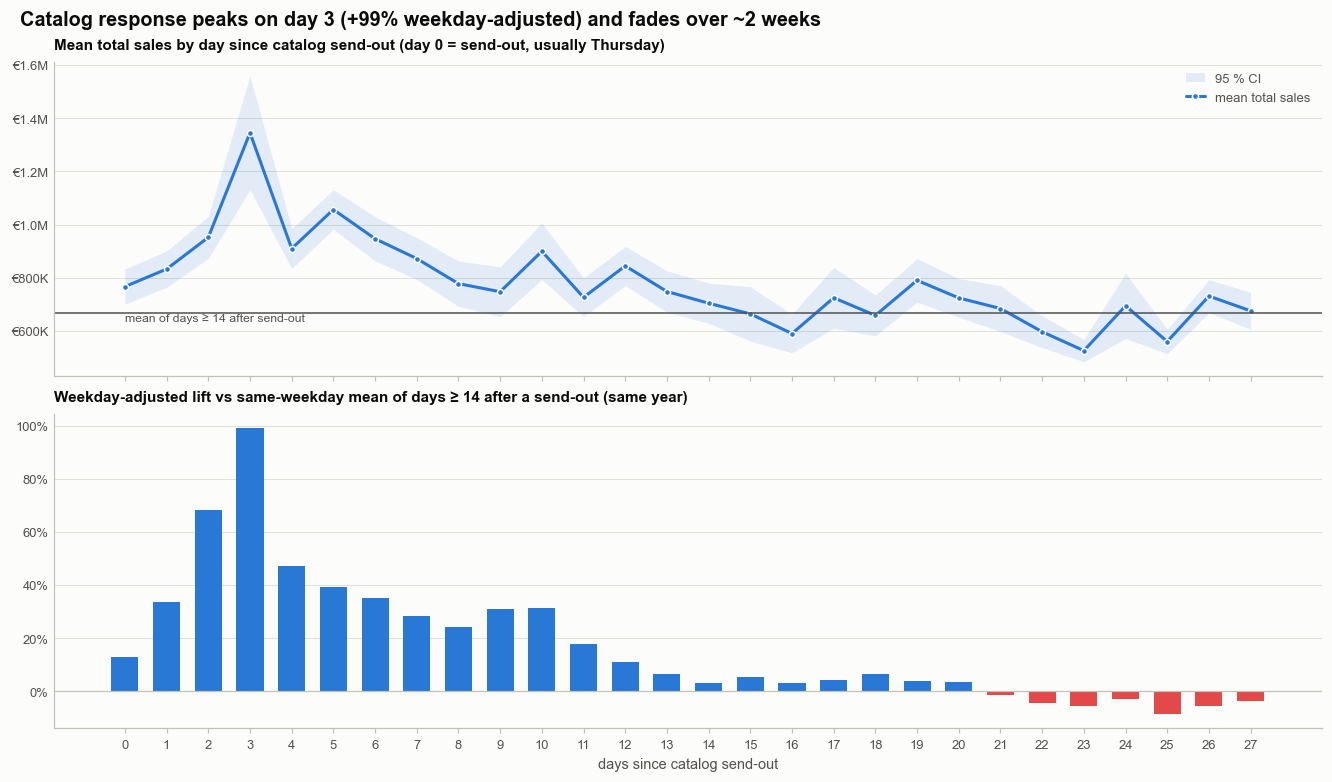

k,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
mean total sales,"€767,259","€833,123","€952,264","€1,345,163","€910,247","€1,056,954","€947,048","€872,622","€778,337","€748,039","€899,803","€726,972","€844,866","€748,847","€704,785"
weekday-adjusted lift,+13%,+34%,+68%,+99%,+47%,+39%,+35%,+28%,+24%,+31%,+31%,+18%,+11%,+6%,+3%
send-outs,28,28,28,28,28,28,28,28,28,28,28,28,28,28,28


In [44]:
ds = cal["days_since_catalog"]
base_mask = ds >= 14
weekday_base = y[base_mask].groupby([cal.loc[base_mask, "year"], cal.loc[base_mask, "dow"]]).mean()
lift = y / weekday_base.reindex(pd.MultiIndex.from_arrays([cal["year"], cal["dow"]])).values - 1

window = ds.between(0, 27)
event = pd.DataFrame({"sales": y[window], "lift": lift[window], "k": ds[window].astype(int)})
agg = event.groupby("k").agg(mean=("sales", "mean"), sd=("sales", "std"), n=("sales", "size"),
                             lift=("lift", "mean"))
agg["ci"] = 1.96 * agg["sd"] / np.sqrt(agg["n"])
baseline_level = y[base_mask].mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
ax = axes[0]
ax.fill_between(agg.index, agg["mean"] - agg["ci"], agg["mean"] + agg["ci"], color=ACCENT, alpha=0.12, lw=0,
                label="95 % CI")
ax.plot(agg.index, agg["mean"], color=ACCENT, lw=2, marker="o", ms=4, mec=SURFACE, label="mean total sales")
ax.axhline(baseline_level, color=INK_2, lw=1)
ax.text(0, baseline_level, "mean of days ≥ 14 after send-out", ha="left", va="top", fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(EUR)
ax.legend(loc="upper right")
ax.set_title("Mean total sales by day since catalog send-out (day 0 = send-out, usually Thursday)", fontsize=10)

ax = axes[1]
ax.bar(agg.index, agg["lift"], color=[ACCENT if v >= 0 else NEGATIVE for v in agg["lift"]], width=0.65)
ax.axhline(0, color=AXIS, lw=0.8)
ax.yaxis.set_major_formatter(PCT)
ax.set_title("Weekday-adjusted lift vs same-weekday mean of days ≥ 14 after a send-out (same year)", fontsize=10)
ax.set_xticks(range(0, 28))
ax.set_xlabel("days since catalog send-out")
headline(fig, f"Catalog response peaks on day 3 (+{agg.loc[3, 'lift']:.0%} weekday-adjusted) and fades over ~2 weeks")
save(fig, "catalog_event_study")
plt.show()
event_table_k = agg.loc[:14, ["mean", "lift", "n"]].T.rename(
    index={"mean": "mean total sales", "lift": "weekday-adjusted lift", "n": "send-outs"})
display(event_table_k.style
        .format("€{:,.0f}", subset=pd.IndexSlice[["mean total sales"], :])
        .format("{:+.0%}", subset=pd.IndexSlice[["weekday-adjusted lift"], :])
        .format("{:.0f}", subset=pd.IndexSlice[["send-outs"], :]))

- Day 0 shows only a small lift (+13 %). The response builds on **day 1 (+34 %) and day 2 (+68 %)** and **peaks on day 3 (+99 %)** — the
  Sunday, ~€1.35 M vs a ~€0.67 M baseline. It then decays with weekly echoes (+35–47 % on days 4–6, +31 % on days 9–10) to ~+5 % by
  **day 13–14**; from day 21 sales sit slightly *below* baseline (long gaps between send-outs happen in weaker periods).
- The lift is weekday-adjusted, so the peak is **the catalog, not just Sunday**.
- Modelling consequence: a **delayed-peak adstock** (binomial / Weibull-PDF type) with a max lag of ~21 days, or 0–21 distributed lags.

### 10.2 Halo — which channels get credited for catalog-driven demand?

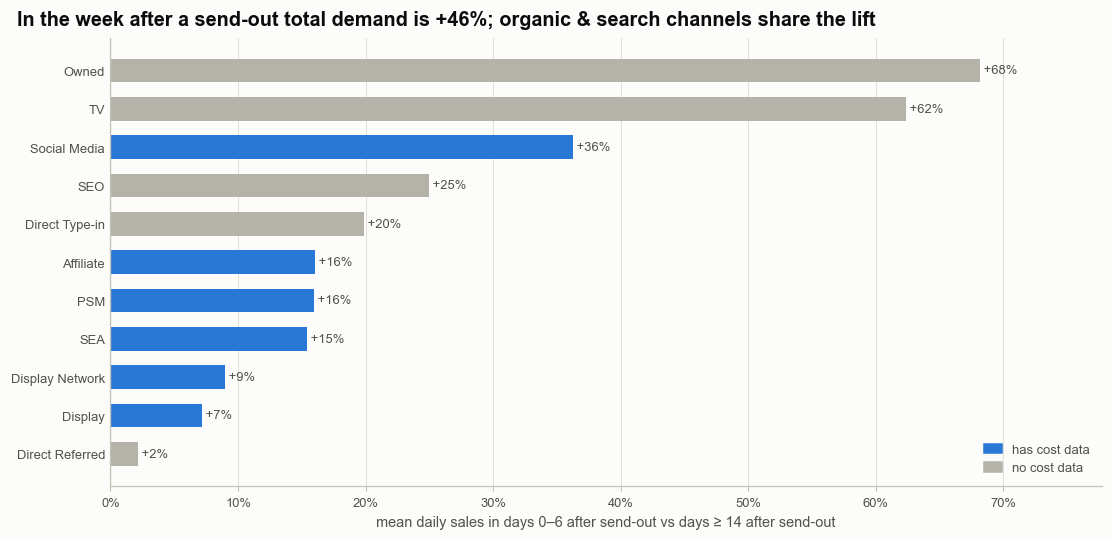

Catalog-attributed sales in days 0–6 vs ≥ 14: +505%
Total demand in days 0–6 vs ≥ 14:           +46%


In [45]:
in_window = ds.between(0, 6)
uplift = (sales[in_window].mean() / sales[base_mask].mean() - 1).drop("Catalog")
total_uplift = y[in_window].mean() / y[base_mask].mean() - 1
catalog_uplift = sales.loc[in_window, "Catalog"].mean() / sales.loc[base_mask, "Catalog"].mean() - 1

fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
ranked_bars(ax, uplift, color={c: (ACCENT if c in PAID else NEUTRAL) for c in CHANNELS}, fmt="{:+.0%}")
ax.xaxis.set_major_formatter(PCT)
ax.set_xlabel("mean daily sales in days 0–6 after send-out vs days ≥ 14 after send-out")
ax.legend(handles=[Patch(color=ACCENT, label="has cost data"), Patch(color=NEUTRAL, label="no cost data")],
          loc="lower right")
headline(fig, f"In the week after a send-out total demand is +{total_uplift:.0%}; organic & search channels share the lift")
save(fig, "catalog_halo")
plt.show()
print(f"Catalog-attributed sales in days 0–6 vs ≥ 14: {catalog_uplift:+.0%}")
print(f"Total demand in days 0–6 vs ≥ 14:           {total_uplift:+.0%}")

In the week after a send-out, catalog-attributed sales are ~6× their tail level (+505 %), and sales credited to **Social (+36 %), SEO
(+25 %), Direct Type-in (+20 %), Affiliate, PSM and SEA (+15–16 %)** all rise as well — customers browse the catalog and then buy via
search or by typing the URL. (The large % for Owned and TV come from tiny, noisy bases.) Display channels barely move (+7–9 %).
Last-touch attribution credits *those* channels, so the catalog's channel-level ROAS (≈ 2.1) **understates** its true contribution. This
is a strong argument for modelling **total** sales (as the brief does) rather than per-channel attributed sales.

### 10.3 How long does the catalog keep selling?

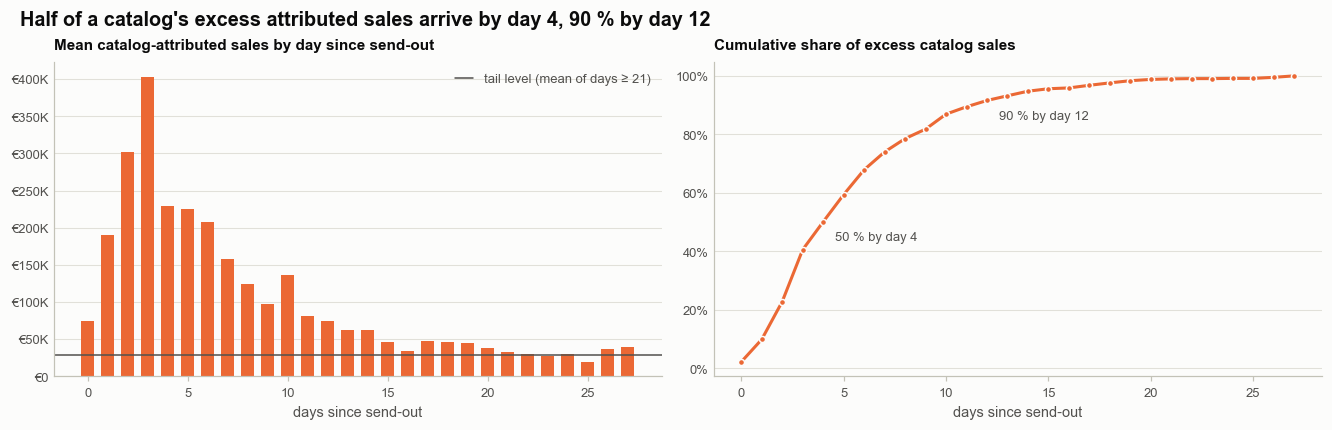

In [46]:
cat_curve = sales["Catalog"].groupby(ds).mean().loc[0:27]
floor = sales.loc[ds >= 21, "Catalog"].mean()
excess = (cat_curve - floor).clip(lower=0)
cum_share = excess.cumsum() / excess.sum()
half_day = int(cum_share[cum_share >= 0.5].index[0])
p90_day = int(cum_share[cum_share >= 0.9].index[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
axes[0].bar(cat_curve.index, cat_curve.values, color=COLOR["Catalog"], width=0.65)
axes[0].axhline(floor, color=INK_2, lw=1, label="tail level (mean of days ≥ 21)")
axes[0].legend(loc="upper right")
axes[0].yaxis.set_major_formatter(EUR)
axes[0].set_title("Mean catalog-attributed sales by day since send-out", fontsize=10)
axes[0].set_xlabel("days since send-out")
axes[1].plot(cum_share.index, cum_share.values, color=COLOR["Catalog"], lw=2, marker="o", ms=4, mec=SURFACE)
for d, label in [(half_day, "50 %"), (p90_day, "90 %")]:
    axes[1].annotate(f"{label} by day {d}", (d, cum_share[d]), xytext=(8, -12), textcoords="offset points",
                     fontsize=8.5, color=INK_2)
axes[1].yaxis.set_major_formatter(PCT)
axes[1].set_title("Cumulative share of excess catalog sales", fontsize=10)
axes[1].set_xlabel("days since send-out")
headline(fig, f"Half of a catalog's excess attributed sales arrive by day {half_day}, 90 % by day {p90_day}")
save(fig, "catalog_decay")
plt.show()

The catalog's own attributed sales confirm the shape: a delayed peak on day 3 and a long tail. These two numbers (50 % / 90 % horizons)
are useful **priors** for the catalog adstock (peak delay ≈ 3 days, effective duration ≈ 2–3 weeks).

### 10.4 Natural experiment — the 42-day gap in autumn 2023

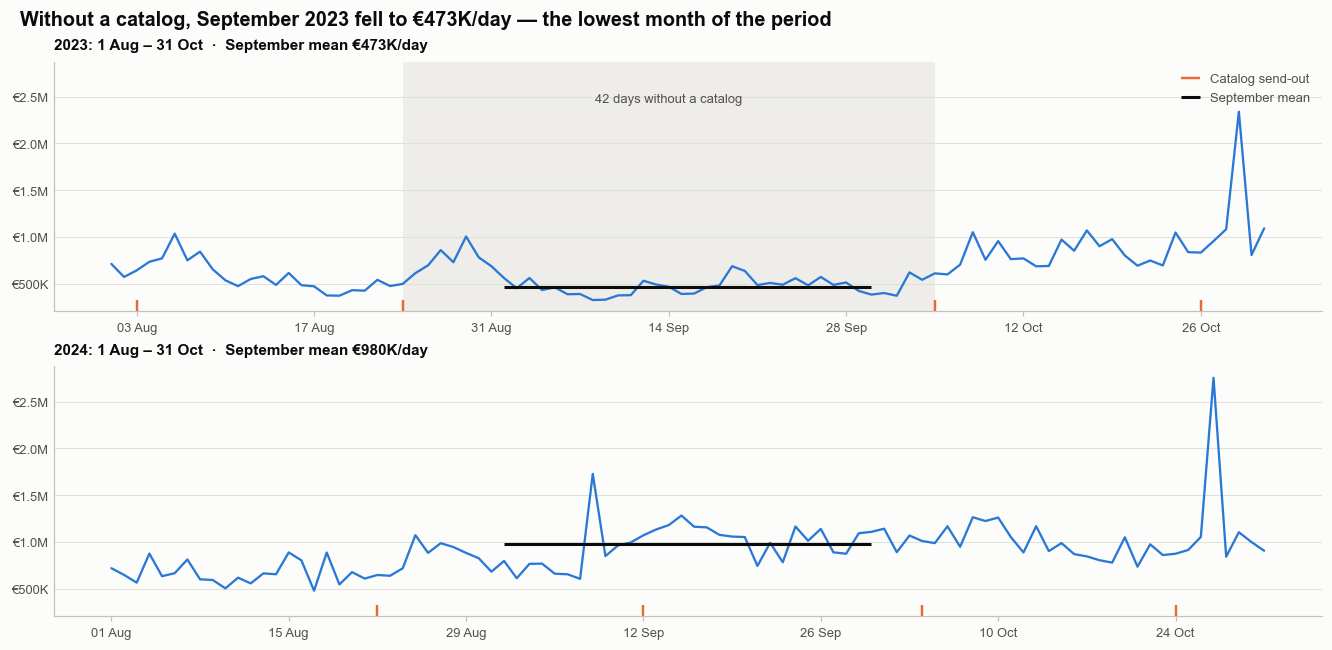

In [47]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.8), sharey=True, layout="constrained")
for ax, yr in zip(axes, (2023, 2024)):
    w = y.loc[f"{yr}-08-01":f"{yr}-10-31"]
    ax.plot(w.index, w.values, color=ACCENT, lw=1.5)
    catalog_rug(ax, send_dates[(send_dates >= w.index[0]) & (send_dates <= w.index[-1])])
    sep = y.loc[f"{yr}-09"].mean()
    ax.hlines(sep, pd.Timestamp(f"{yr}-09-01"), pd.Timestamp(f"{yr}-09-30"), color=INK, lw=2,
              label="September mean" if yr == 2023 else None)
    ax.set_title(f"{yr}: 1 Aug – 31 Oct  ·  September mean {compact(sep)}/day", fontsize=10)
    ax.yaxis.set_major_formatter(EUR)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.TH, interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].axvspan(pd.Timestamp("2023-08-24"), pd.Timestamp("2023-10-05"), color=GRID, alpha=0.5, lw=0)
axes[0].text(pd.Timestamp("2023-09-14"), axes[0].get_ylim()[1] * 0.85, "42 days without a catalog",
             ha="center", fontsize=8.5, color=INK_2)
axes[0].legend(loc="upper right")
headline(fig, "Without a catalog, September 2023 fell to €473K/day — the lowest month of the period")
save(fig, "catalog_natural_experiment")
plt.show()

The only long catalog pause (24 Aug → 5 Oct 2023) coincides with the **weakest month in the data** (Sept 2023: €473 K/day vs €980 K/day
in Sept 2024). Part of the gap is the 2024 growth trend and Social Media's new regime, but the drop *within* 2023 (Aug → Sep) and the
rebound right after the 5 Oct send-out make the catalog's role visible without any model. It also shows the catalog creates demand that
is not simply shifted from other weeks.

### 10.5 Does a bigger catalog lift more?

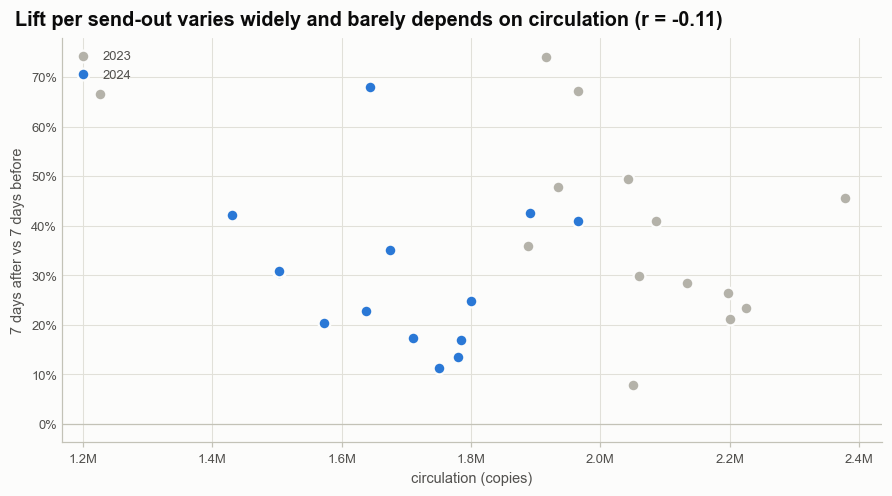

Median 7-day lift per send-out: +31% (range +8% to +74%)
Median lift by year: {2023: '+38%', 2024: '+28%'}


In [48]:
per_send = []
for d in send_dates:
    before = y.loc[d - pd.Timedelta(days=7): d - pd.Timedelta(days=1)].mean()
    after = y.loc[d: d + pd.Timedelta(days=6)].mean()
    per_send.append({"date": d, "circulation": impr_wide.loc[d, "Catalog"],
                     "cost": cost.loc[d, "Catalog"], "lift": after / before - 1})
per_send = pd.DataFrame(per_send).set_index("date")

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
for yr, color in [(2023, NEUTRAL), (2024, ACCENT)]:
    d = per_send[per_send.index.year == yr]
    ax.scatter(d["circulation"], d["lift"], s=60, color=color, edgecolor=SURFACE, linewidth=1.5, label=str(yr))
ax.xaxis.set_major_formatter(NUM)
ax.yaxis.set_major_formatter(PCT)
ax.axhline(0, color=AXIS, lw=0.8)
ax.grid(axis="x", visible=True)
ax.set_xlabel("circulation (copies)")
ax.set_ylabel("7 days after vs 7 days before")
ax.legend(loc="upper left")
r = per_send["circulation"].corr(per_send["lift"])
headline(fig, f"Lift per send-out varies widely and barely depends on circulation (r = {r:.2f})")
save(fig, "catalog_lift_vs_circulation")
plt.show()
print(f"Median 7-day lift per send-out: {per_send['lift'].median():+.0%} "
      f"(range {per_send['lift'].min():+.0%} to {per_send['lift'].max():+.0%})")
print("Median lift by year:", per_send.groupby(per_send.index.year)["lift"].median().map("{:+.0%}".format).to_dict())

Every send-out lifts the following week (median +31 %, range +8 % to +74 %), but the size of the lift is unrelated to circulation within
the observed range (~1.2 M – 2.4 M copies) — content and season, which we do not observe, matter more. The median lift was lower in
2024 (+28 %) than in 2023 (+38 %), when circulation was ~16 % higher, but with ~14 events per year that difference is not conclusive.
A catalog **event indicator plus lag structure** captures most of the signal; the circulation-response (saturation) curve cannot be
learned well from this data.

## 11. MMM readiness

An MMM can only separate channel effects if each channel's spend moves *independently* of the others and of the season. The table
summarises that for each paid channel.

In [49]:
diag = {}
for ch in PAID:
    s = cost[ch]
    log_s = np.log1p(s)
    fitted = log_s - residualize(log_s, X_cal)
    others = cost[PAID].drop(columns=ch)
    diag[ch] = {
        "active days": (s > 0).mean(),
        "CV daily spend": s.std() / s.mean(),
        "spend variance explained by trend + calendar (R²)": 1 - np.var(log_s - fitted) / np.var(log_s),
        "max |r| with another channel's spend": others.corrwith(s).abs().max(),
        "r with total sales (same day)": s.corr(y),
        "r with total sales (best lag 0–21)": max(y.corr(s.shift(k)) for k in range(22)),
        "best lag": int(np.argmax([y.corr(s.shift(k)) for k in range(22)])),
    }
diag = pd.DataFrame(diag).T
display(
    diag.style.format({
        "active days": "{:.0%}", "CV daily spend": "{:.2f}",
        "spend variance explained by trend + calendar (R²)": "{:.0%}",
        "max |r| with another channel's spend": "{:.2f}", "r with total sales (same day)": "{:.2f}",
        "r with total sales (best lag 0–21)": "{:.2f}", "best lag": "{:.0f}",
    }).background_gradient(cmap=SEQ, subset=["spend variance explained by trend + calendar (R²)"], vmin=0, vmax=1)
)

,active days,CV daily spend,spend variance explained by trend + calendar (R²),max |r| with another channel's spend,r with total sales (same day),r with total sales (best lag 0–21),best lag
SEA,100%,0.36,52%,0.58,0.72,0.72,0
Catalog,4%,5.06,21%,0.04,-0.01,0.40,3
Display,100%,0.39,33%,0.58,0.56,0.56,0
Affiliate,100%,0.75,52%,0.50,0.76,0.76,0
Social Media,100%,1.14,38%,0.51,0.33,0.43,20
Display Network,100%,0.48,33%,0.58,0.44,0.44,0
PSM,100%,0.34,49%,0.56,0.49,0.49,0


**Reading the table**

- **Catalog** is the best-identified medium: it is pulsed (active on 4 % of days, high CV), almost independent of the calendar and of
  other channels → its effect can be estimated well, *if* the lag structure is right.
- **Digital channels** are always on, and **33–52 %** of their (log) spend variance is explained by trend + calendar alone (most for SEA,
  Affiliate and PSM) → much of their variation is *seasonal planning*, and each also correlates 0.50–0.58 with another channel's spend.
  Their individual effects will be **weakly identified**; regularisation or informative priors (Meridian) are required, and
  coefficients will be sensitive to specification.
- **Affiliate** and **SEA** have the highest raw correlation with sales, but their cost is partly a *function* of sales (commission / CPC) —
  correlation ≠ causation. Social Media's "best lag" of 20 days is noise, not a real delay.

**Sample size.** 732 daily observations (104 complete weeks). With 7 media channels × (coefficient + adstock + saturation parameters)
≈ 21–28 media parameters plus trend, weekday, yearly Fourier and holiday controls, a **daily** model has enough degrees of freedom;
a weekly model would be tight. Only **two Q4s and two Black Fridays** exist, so peak-season effects carry the most uncertainty.

**Proposed MMM roles**

| Channel | Role | Exposure input | Adstock prior | Notes |
|---|---|---|---|---|
| Catalog | paid media | circulation (spend for ROI) | delayed peak ≈ day 3, ~21-day max lag | best identified; halo → model total sales |
| SEA | paid media | clicks / spend | short geometric | CPC-billed → partly demand-driven |
| Display | paid media | impressions | geometric | always on, seasonal |
| Social Media | paid media | impressions | geometric | **regime change 1 Aug 2024** |
| Affiliate | paid media *(caution)* | spend | short | commission → reverse causality; rate change Feb 2024; consider excluding or lagging |
| Display Network | paid media | impressions | geometric | small budget |
| PSM | paid media | clicks | short | no impressions |
| Direct Type-in, SEO, Direct Referred, Owned | **target only** | – | – | organic / baseline |
| TV | **target only** | – | – | sales but no costs; outages |

## 12. Answers to the case-study questions

### Q1 — What conclusions do we draw from the channel interactions and the data?

1. **Timing matters more than size of correlation.** The catalog — the largest budget — has zero same-day correlation with sales
   (−0.01) but 0.40 at a 3-day lag and drives the biggest demand peaks: the response peaks **3 days after send-out (+99 %)** and fades
   over ~2 weeks.
2. **Channels interact (halo).** In the week after a send-out total demand is +46 %, and sales credited to SEO, Direct Type-in, Social,
   Affiliate, PSM and SEA rise by 15–36 %. Attributed channel sales are therefore *not* independent effects, and attributed ROAS
   understates upper-funnel media (Catalog 2.1, Display 2.2) and flatters lower-funnel channels (Affiliate 8.2, SEA 3.9).
3. **Digital budgets move together and with the season** (pairwise r 0.22–0.58; 33–52 % of their spend variance explained by trend +
   calendar) → individual digital effects are hard to separate; much of their raw correlation with sales is shared seasonality.
4. **Some costs are consequences of demand.** Affiliate cost is a commission on affiliate sales (r = 0.80, ~7–12 % in 2023, ~15 % from
   Feb 2024); SEA is click-billed (cost↔clicks 0.96). Their correlation with sales (0.76 / 0.72) survives de-seasonalising — reverse
   causality, not proof of effectiveness.
5. **Strong calendar structure:** upward trend (+20.7 % YoY), Q4 peak, weekday cycle (Tuesday strong in all channels, Sunday strong
   mainly because of the catalog), Christmas/holiday troughs (down to −79 %), Black Friday peak (+33 % / +57 %).
6. **Structural breaks:** Social Media changed regime on 1 Aug 2024 (spend ×3.7, clicks ×16, attributed sales ×10 Aug–Dec vs Jan–Jul);
   Affiliate's commission rate doubled in Feb 2024.
7. **Diminishing returns:** sales grow roughly with log(spend); part of the raw spend–sales relationship is trend and season.

### Q2 — What obstacles exist for further processing?

- **Format:** long, shuffled rows → sort and pivot; NaN means different things (not applicable vs zero spend vs missing).
- **Gaps / outages:** TV (38 + 8 days), Catalog (4), Owned (2); one isolated 2025 day.
- **Lumpy, mis-timed costs:** catalog cost booked on the send-out day; effect arrives days later → adstock / distributed lags needed.
- **Very different scales** (€2.7 K/day PSM vs €1.7 M catalog days) → transformation and standardisation.
- **Multicollinearity** and **reverse causality** (budget follows expected demand; CPC/commission costs follow realised demand).
- **Media inflation:** CPC / CPM / cost per catalog copy drift over time → the same budget buys different exposure.
- **Structural breaks** in Social Media (Aug 2024) and Affiliate commissions (Feb 2024); **short history** (2 years, 2 Q4s, 28 catalog
  events) → limited ability to learn yearly seasonality and peak-season effects.
- **Missing drivers:** promotions, prices, Tchibo's weekly product worlds, store traffic, weather, competition, TV spend — the most
  likely sources of remaining error.
- **Forecast-time availability:** planned budgets are needed at prediction time; for performance channels (SEA, Affiliate) the plan is
  only a cap, actual cost is known only ex post.

### Q3 — Which of the influencing factors cannot be used?

- **`sales_by_channel` as a feature** — the channels sum to the target → direct **target leakage**.
- **Same-day clicks and impressions** — they are realised outcomes recorded alongside sales, not known in advance for a forecast; they
  are, however, valid *exposure* inputs for an explanatory MMM. PSM has no impressions and Catalog clicks are always 0.
- **TV, SEO, Direct Type-in, Direct Referred, Owned** — no cost data, so they cannot be budget levers; their sales stay in the target.
- **Affiliate cost (with caution)** — commission-based, i.e. an outcome of sales; using realised affiliate cost to predict same-day sales
  leaks demand information. Use planned budget or lagged values only.

## 13. Implications for data preparation & modelling

| Finding | Action in Phase 2 / 3 |
|---|---|
| Rows shuffled, long format | `src/.../data.py`: sort, pivot to a wide daily table (7 cost columns + `total_sales`) |
| NaN semantics differ | catalog NaN → 0 spend; missing channel-days → 0 sales + flag; organic NaN = not applicable |
| Catalog peaks at +3 days, fades ~2–3 weeks | delayed (binomial) adstock or distributed lags 0–21; `days_since_catalog` feature |
| Digital carry-over & saturation | geometric adstock + Hill / log saturation, tuned with time-series CV |
| Trend & level shift | linear / piecewise trend — required for extrapolation (tree models need detrending) |
| Weekly & yearly seasonality | weekday dummies, low-order yearly Fourier terms |
| Holidays & retail events | German holidays, Christmas window, Black Friday / Cyber Week, Easter |
| Right-skewed target, multiplicative effects | model log(sales) or use multiplicative MMM; evaluate on original scale |
| Social Media regime change; Affiliate commission change | regime dummies / interactions from 2024-08-01 and 2024-02 |
| Unexplained peaks (e.g. 8 Sep 2024) | ask for promotion / campaign calendar; robust loss or outlier flag |
| Reverse causality (Affiliate, SEA) | sensitivity analysis with/without; prefer exposure or lagged inputs |
| Multicollinearity | ridge / Bayesian priors (Meridian); interpret channel effects with uncertainty |
| Autocorrelated errors | time-based hold-out (Q4 2024) + walk-forward CV; HAC errors for inference |

**Feature candidates (≥ 2 required by the brief):** catalog adstock / lags & `days_since_catalog`, adstocked-saturated digital spend,
weekday & Fourier seasonality, holiday/event flags, trend, Social regime flag, total spend & digital share, rolling 7-day spend.

In [50]:
print(f"Figures exported to {FIG_DIR.relative_to(ROOT)}:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.name)

Figures exported to reports/figures/eda:
   affiliate_commission.png
   catalog_decay.png
   catalog_event_study.png
   catalog_halo.png
   catalog_lift_vs_circulation.png
   catalog_natural_experiment.png
   catalog_sendouts.png
   channel_mix_monthly.png
   channel_share_growth.png
   channel_small_multiples.png
   channel_weekday_index.png
   corr_channel_sales.png
   corr_cost_vs_channel_sales.png
   corr_matrix_costs.png
   corr_robustness.png
   efficiency_kpis.png
   events_lift.png
   funnel_correlations.png
   lag_correlation.png
   metric_availability.png
   missing_days.png
   peak_season.png
   social_regime_change.png
   spend_response.png
   spend_small_multiples.png
   spend_vs_sales_share.png
   spend_vs_sales_time.png
   spend_weekday_index.png
   target_acf.png
   target_distribution.png
   target_seasonality.png
   target_stl.png
   target_timeseries.png
   target_yoy.png
